# Vertical Federated Unlearning (VFU) Project

This notebook implements a comprehensive framework for Vertical Federated Learning (VFL) with unlearning capabilities.

## Datasets
- **UCI Adult**: 32K census records (income prediction)
- **German Credit**: 1K records (credit risk assessment)
- **MIMIC-III**: 46K ICU patients (healthcare - requires PhysioNet credentials)

## Related Work

### Horizontal Federated Learning (HFL) Unlearning Papers
| Paper | Method | Key Contribution |
|-------|--------|------------------|
| FedEraser (Liu et al., 2021) | Historical gradient storage | First HFL unlearning via calibrated gradient subtraction |
| SISA (Bourtoule et al., 2021) | Sharding + slicing | Partitions data for efficient retraining |
| FedRecover (Cao et al., 2023) | Gradient-based recovery | Efficient recovery without full retraining |
| KNOT (Su et al., 2023) | Knowledge distillation | Teacher-student unlearning framework |
| FRU (Yuan et al., 2023) | Rapid unlearning | Channel pruning + fine-tuning |

### Vertical Federated Learning (VFL) Unlearning Papers
| Paper | Method | Key Contribution |
|-------|--------|------------------|
| VFU-LR (Deng et al., 2023) | Constraint-based | 400% efficiency improvement over retraining |
| Few-shot Label Unlearning (Gu et al., 2024) | Mixup + gradient ascent | Unlearning in seconds |
| VFU-KD/VFU-GA (Varshney et al., 2025) | Knowledge distillation / gradient ascent | Client, feature, sample unlearning |
| Certified VFL Unlearning (Wang & Wang, 2025) | Theoretically certified | Asynchronous unlearning support |


## 1. Environment Setup


In [1]:
# Install required packages (uncomment if needed)
# !pip install pandas numpy scikit-learn torch matplotlib seaborn


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.linear_model import LogisticRegression
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


## 2. Dataset Loading and Preprocessing

### 2.1 UCI Adult Dataset (32K Census Records)


In [3]:
def load_adult_dataset():
    """Load UCI Adult dataset for income prediction."""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
    columns = [
        'age', 'workclass', 'fnlwgt', 'education', 'education_num',
        'marital_status', 'occupation', 'relationship', 'race', 'sex',
        'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
    ]
    
    df = pd.read_csv(url, names=columns, sep=',\\s*', engine='python', na_values='?')
    df = df.dropna()
    
    # Encode target
    df['income'] = (df['income'] == '>50K').astype(int)
    
    # Encode categorical features
    categorical_cols = ['workclass', 'education', 'marital_status', 'occupation', 
                        'relationship', 'race', 'sex', 'native_country']
    
    for col in categorical_cols:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])
    
    X = df.drop('income', axis=1)
    y = df['income']
    
    return X, y

# Load dataset
X_adult, y_adult = load_adult_dataset()
print(f"UCI Adult Dataset: {X_adult.shape[0]} samples, {X_adult.shape[1]} features")
print(f"Class distribution: {y_adult.value_counts().to_dict()}")


UCI Adult Dataset: 30162 samples, 14 features
Class distribution: {0: 22654, 1: 7508}


### 2.2 German Credit Dataset (1K Records)


In [4]:
def load_german_credit_dataset():
    """Load German Credit dataset for credit risk assessment."""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
    
    # Column names based on dataset documentation
    columns = [
        'checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount',
        'savings_status', 'employment', 'installment_rate', 'personal_status',
        'other_parties', 'residence_since', 'property_magnitude', 'age',
        'other_payment_plans', 'housing', 'existing_credits', 'job',
        'num_dependents', 'own_telephone', 'foreign_worker', 'class'
    ]
    
    df = pd.read_csv(url, names=columns, sep=' ')
    
    # Encode target (1 = Good, 2 = Bad) -> (1 = Good, 0 = Bad)
    df['class'] = (df['class'] == 1).astype(int)
    
    # Encode categorical features
    categorical_cols = ['checking_status', 'credit_history', 'purpose', 'savings_status',
                        'employment', 'personal_status', 'other_parties', 'property_magnitude',
                        'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']
    
    for col in categorical_cols:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
    
    X = df.drop('class', axis=1)
    y = df['class']
    
    return X, y

# Load dataset
X_german, y_german = load_german_credit_dataset()
print(f"German Credit Dataset: {X_german.shape[0]} samples, {X_german.shape[1]} features")
print(f"Class distribution: {y_german.value_counts().to_dict()}")


German Credit Dataset: 1000 samples, 20 features
Class distribution: {1: 700, 0: 300}


### 2.3 MIMIC-III Dataset (Healthcare - Placeholder)

MIMIC-III requires credentialed access from PhysioNet: https://physionet.org/content/mimiciii/

Steps to access:
1. Complete CITI training
2. Sign data use agreement
3. Download via PhysioNet


In [5]:
def load_mimic_iii_dataset(mimic_path=None):
    """
    Load MIMIC-III dataset for mortality prediction.
    
    Args:
        mimic_path: Path to MIMIC-III data directory
        
    Returns:
        X, y: Features and labels for ICU mortality prediction
        
    Note: Requires credentialed access from PhysioNet.
    """
    if mimic_path is None:
        print("MIMIC-III dataset requires credentialed access.")
        print("Please download from: https://physionet.org/content/mimiciii/")
        print("\nUsing synthetic placeholder data for demonstration...")
        
        # Generate synthetic healthcare data for demonstration
        n_samples = 46000
        np.random.seed(SEED)
        
        # Simulate ICU features
        X = pd.DataFrame({
            'age': np.random.normal(65, 15, n_samples).clip(18, 95),
            'heart_rate': np.random.normal(80, 20, n_samples).clip(40, 180),
            'blood_pressure_systolic': np.random.normal(120, 25, n_samples).clip(60, 200),
            'blood_pressure_diastolic': np.random.normal(80, 15, n_samples).clip(40, 120),
            'respiratory_rate': np.random.normal(18, 5, n_samples).clip(8, 40),
            'temperature': np.random.normal(37, 1, n_samples).clip(34, 42),
            'oxygen_saturation': np.random.normal(96, 3, n_samples).clip(70, 100),
            'glucose': np.random.normal(120, 40, n_samples).clip(40, 400),
            'creatinine': np.random.exponential(1.2, n_samples).clip(0.3, 10),
            'bun': np.random.normal(20, 10, n_samples).clip(5, 100),
            'sodium': np.random.normal(140, 5, n_samples).clip(120, 160),
            'potassium': np.random.normal(4, 0.5, n_samples).clip(2.5, 7),
            'hemoglobin': np.random.normal(12, 2, n_samples).clip(5, 18),
            'wbc': np.random.exponential(10, n_samples).clip(1, 50),
            'platelets': np.random.normal(250, 100, n_samples).clip(20, 600),
            'icu_los': np.random.exponential(5, n_samples).clip(0.5, 60),  # Length of stay
            'gender': np.random.binomial(1, 0.55, n_samples),
            'ventilator': np.random.binomial(1, 0.3, n_samples),
            'vasopressor': np.random.binomial(1, 0.2, n_samples),
            'dialysis': np.random.binomial(1, 0.1, n_samples),
        })
        
        # Generate mortality labels (correlated with features)
        mortality_prob = 0.1 + 0.15 * (X['age'] > 70) + 0.2 * (X['ventilator'] == 1) + \
                        0.15 * (X['vasopressor'] == 1) + 0.1 * (X['creatinine'] > 2)
        mortality_prob = mortality_prob.clip(0, 0.9)
        y = (np.random.random(n_samples) < mortality_prob).astype(int)
        
        return X, pd.Series(y)
    
    # Load actual MIMIC-III data
    # Implementation depends on your specific preprocessing pipeline
    # Common tables: ADMISSIONS, PATIENTS, ICUSTAYS, CHARTEVENTS, LABEVENTS
    pass

# Load dataset (placeholder)
X_mimic, y_mimic = load_mimic_iii_dataset()
print(f"\nMIMIC-III Dataset: {X_mimic.shape[0]} samples, {X_mimic.shape[1]} features")
print(f"Class distribution: {y_mimic.value_counts().to_dict()}")


MIMIC-III dataset requires credentialed access.
Please download from: https://physionet.org/content/mimiciii/

Using synthetic placeholder data for demonstration...

MIMIC-III Dataset: 46000 samples, 20 features
Class distribution: {0: 33825, 1: 12175}


## 3. Vertical Federated Learning Data Partitioning

In VFL, different parties hold different features of the same samples.


In [6]:
class VFLDataPartitioner:
    """Partition data vertically for VFL simulation."""
    
    def __init__(self, X, y, n_parties=2, label_party=0, random_state=42):
        """
        Args:
            X: Feature DataFrame
            y: Labels
            n_parties: Number of parties
            label_party: Which party holds the labels (active party)
            random_state: Random seed for reproducibility
        """
        self.X = X
        self.y = y
        self.n_parties = n_parties
        self.label_party = label_party
        self.random_state = random_state
        
        self.feature_splits = None
        self.party_data = None
        
    def partition_features(self, method='equal', custom_splits=None):
        """
        Partition features among parties.
        
        Args:
            method: 'equal', 'random', or 'custom'
            custom_splits: List of feature lists for each party
        """
        np.random.seed(self.random_state)
        all_features = list(self.X.columns)
        
        if method == 'custom' and custom_splits is not None:
            self.feature_splits = custom_splits
        elif method == 'equal':
            np.random.shuffle(all_features)
            split_size = len(all_features) // self.n_parties
            self.feature_splits = []
            for i in range(self.n_parties):
                start = i * split_size
                if i == self.n_parties - 1:
                    self.feature_splits.append(all_features[start:])
                else:
                    self.feature_splits.append(all_features[start:start + split_size])
        elif method == 'random':
            # Random assignment with overlap prevention
            np.random.shuffle(all_features)
            sizes = np.random.dirichlet(np.ones(self.n_parties)) * len(all_features)
            sizes = np.round(sizes).astype(int)
            sizes[-1] = len(all_features) - sum(sizes[:-1])
            
            self.feature_splits = []
            start = 0
            for size in sizes:
                self.feature_splits.append(all_features[start:start + int(size)])
                start += int(size)
        
        # Create party data
        self.party_data = []
        for i in range(self.n_parties):
            party_X = self.X[self.feature_splits[i]]
            party_y = self.y if i == self.label_party else None
            self.party_data.append({
                'X': party_X,
                'y': party_y,
                'features': self.feature_splits[i],
                'is_active': i == self.label_party
            })
            
        return self.party_data
    
    def get_party_data(self, party_id):
        """Get data for a specific party."""
        return self.party_data[party_id]
    
    def summary(self):
        """Print partition summary."""
        print("VFL Data Partition Summary")
        print("=" * 50)
        for i, party in enumerate(self.party_data):
            party_type = "Active (has labels)" if party['is_active'] else "Passive"
            print(f"Party {i} [{party_type}]:")
            print(f"  Features: {len(party['features'])}")
            print(f"  Feature names: {party['features'][:5]}..." if len(party['features']) > 5 else f"  Feature names: {party['features']}")
        print("=" * 50)


In [7]:
# Partition UCI Adult dataset for VFL
partitioner_adult = VFLDataPartitioner(X_adult, y_adult, n_parties=2, label_party=0)
adult_parties = partitioner_adult.partition_features(method='equal')
partitioner_adult.summary()


VFL Data Partition Summary
Party 0 [Active (has labels)]:
  Features: 7
  Feature names: ['sex', 'capital_loss', 'age', 'hours_per_week', 'marital_status']...
Party 1 [Passive]:
  Features: 7
  Feature names: ['workclass', 'native_country', 'education_num', 'relationship', 'capital_gain']...


In [8]:
# Partition German Credit dataset for VFL
partitioner_german = VFLDataPartitioner(X_german, y_german, n_parties=2, label_party=0)
german_parties = partitioner_german.partition_features(method='equal')
partitioner_german.summary()


VFL Data Partition Summary
Party 0 [Active (has labels)]:
  Features: 10
  Feature names: ['checking_status', 'num_dependents', 'existing_credits', 'duration', 'personal_status']...
Party 1 [Passive]:
  Features: 10
  Feature names: ['other_payment_plans', 'credit_history', 'other_parties', 'foreign_worker', 'credit_amount']...


In [9]:
# Partition MIMIC-III dataset for VFL (3 parties: Hospital, Lab, Demographics)
# Custom split based on feature types
hospital_features = ['heart_rate', 'blood_pressure_systolic', 'blood_pressure_diastolic', 
                     'respiratory_rate', 'oxygen_saturation', 'icu_los', 'ventilator', 
                     'vasopressor', 'dialysis']
lab_features = ['glucose', 'creatinine', 'bun', 'sodium', 'potassium', 
                'hemoglobin', 'wbc', 'platelets', 'temperature']
demographic_features = ['age', 'gender']

partitioner_mimic = VFLDataPartitioner(X_mimic, y_mimic, n_parties=3, label_party=0)
mimic_parties = partitioner_mimic.partition_features(
    method='custom', 
    custom_splits=[hospital_features, lab_features, demographic_features]
)
partitioner_mimic.summary()


VFL Data Partition Summary
Party 0 [Active (has labels)]:
  Features: 9
  Feature names: ['heart_rate', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'respiratory_rate', 'oxygen_saturation']...
Party 1 [Passive]:
  Features: 9
  Feature names: ['glucose', 'creatinine', 'bun', 'sodium', 'potassium']...
Party 2 [Passive]:
  Features: 2
  Feature names: ['age', 'gender']


## 4. VFL Model Architecture

Split learning architecture where each party has a bottom model and the active party has the top model.


In [10]:
class BottomModel(nn.Module):
    """Bottom model for each party in VFL."""
    
    def __init__(self, input_dim, hidden_dim=64, output_dim=32):
        super(BottomModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, output_dim),
            nn.ReLU()
        )
        
    def forward(self, x):
        return self.network(x)


class TopModel(nn.Module):
    """Top model for the active party in VFL."""
    
    def __init__(self, input_dim, hidden_dim=64, output_dim=1):
        super(TopModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, output_dim),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        return self.network(x)


In [11]:
class VFLModel:
    """Vertical Federated Learning Model with Split Learning."""
    
    def __init__(self, party_data, embedding_dim=32, hidden_dim=64, device='cpu'):
        self.party_data = party_data
        self.n_parties = len(party_data)
        self.device = device
        self.embedding_dim = embedding_dim
        
        # Create bottom models for each party
        self.bottom_models = []
        for party in party_data:
            input_dim = len(party['features'])
            model = BottomModel(input_dim, hidden_dim, embedding_dim).to(device)
            self.bottom_models.append(model)
        
        # Create top model (concatenates all embeddings)
        top_input_dim = embedding_dim * self.n_parties
        self.top_model = TopModel(top_input_dim, hidden_dim, 1).to(device)
        
        # Store gradients for unlearning
        self.gradient_history = []
        
    def forward(self, X_parties):
        """Forward pass through all bottom models and top model."""
        embeddings = []
        for i, (model, X) in enumerate(zip(self.bottom_models, X_parties)):
            emb = model(X)
            embeddings.append(emb)
        
        # Concatenate embeddings
        combined = torch.cat(embeddings, dim=1)
        output = self.top_model(combined)
        return output, embeddings
    
    def get_all_parameters(self):
        """Get all trainable parameters."""
        params = []
        for model in self.bottom_models:
            params.extend(list(model.parameters()))
        params.extend(list(self.top_model.parameters()))
        return params
    
    def state_dict(self):
        """Get state dictionary for all models (for saving/loading)."""
        state = {
            'top_model': self.top_model.state_dict(),
            'bottom_models': [m.state_dict() for m in self.bottom_models]
        }
        return state
    
    def load_state_dict(self, state):
        """Load state dictionary into all models."""
        self.top_model.load_state_dict(state['top_model'])
        for i, m_state in enumerate(state['bottom_models']):
            self.bottom_models[i].load_state_dict(m_state)


## 5. VFL Training Framework


In [12]:
class VFLTrainer:
    """Trainer for Vertical Federated Learning with unlearning support."""

    def __init__(self, vfl_model, learning_rate=0.001):
        self.model = vfl_model
        self.criterion = nn.BCELoss()
        self.optimizer = optim.Adam(self.model.get_all_parameters(), lr=learning_rate)

        # Training history for unlearning
        self.training_history = []
        self.party_data = vfl_model.party_data

    def prepare_data(self, party_data, test_size=0.2):
        """Prepare data loaders for training."""
        # Get data from each party
        X_list = [party['X'].values.astype(np.float32) for party in party_data]

        # Get labels from active party
        y = None
        for party in party_data:
            if party['is_active']:
                y = party['y'].values.astype(np.float32)
                break

        # Normalize features
        scalers = []
        X_scaled = []
        for X in X_list:
            scaler = StandardScaler()
            X_scaled.append(scaler.fit_transform(X))
            scalers.append(scaler)

        # Train-test split (same indices for all parties)
        indices = np.arange(len(y))
        train_idx, test_idx = train_test_split(indices, test_size=test_size, random_state=42)

        self.train_idx = train_idx
        self.test_idx = test_idx

        # Create tensors
        X_train = [torch.FloatTensor(X[train_idx]).to(self.model.device) for X in X_scaled]
        X_test = [torch.FloatTensor(X[test_idx]).to(self.model.device) for X in X_scaled]
        y_train = torch.FloatTensor(y[train_idx]).unsqueeze(1).to(self.model.device)
        y_test = torch.FloatTensor(y[test_idx]).unsqueeze(1).to(self.model.device)

        return X_train, X_test, y_train, y_test, scalers

    def train_epoch(self, X_train, y_train, batch_size=256):
        """Train for one epoch."""
        n_samples = y_train.shape[0]
        indices = np.random.permutation(n_samples)

        total_loss = 0
        n_batches = 0

        for model in self.model.bottom_models:
            model.train()
        self.model.top_model.train()

        for start in range(0, n_samples, batch_size):
            end = min(start + batch_size, n_samples)
            batch_idx = indices[start:end]

            # Get batch data for each party
            X_batch = [X[batch_idx] for X in X_train]
            y_batch = y_train[batch_idx]

            # Forward pass
            self.optimizer.zero_grad()
            output, _ = self.model.forward(X_batch)
            loss = self.criterion(output, y_batch)

            # Backward pass
            loss.backward()
            self.optimizer.step()

            total_loss += loss.item()
            n_batches += 1

        return total_loss / n_batches

    def evaluate(self, X_test, y_test):
        """Evaluate the model."""
        for model in self.model.bottom_models:
            model.eval()
        self.model.top_model.eval()

        with torch.no_grad():
            output, _ = self.model.forward(X_test)
            predictions = (output > 0.5).float()

            y_true = y_test.cpu().numpy()
            y_pred = predictions.cpu().numpy()
            y_prob = output.cpu().numpy()

            acc = accuracy_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred)
            auc = roc_auc_score(y_true, y_prob)

        return {'accuracy': acc, 'f1': f1, 'auc': auc}

    def train(self, X_train, X_test, y_train, y_test, epochs=50, batch_size=256, verbose=True):
        """Full training loop."""
        history = {'train_loss': [], 'val_acc': [], 'val_f1': [], 'val_auc': []}

        for epoch in range(epochs):
            loss = self.train_epoch(X_train, y_train, batch_size)
            metrics = self.evaluate(X_test, y_test)

            history['train_loss'].append(loss)
            history['val_acc'].append(metrics['accuracy'])
            history['val_f1'].append(metrics['f1'])
            history['val_auc'].append(metrics['auc'])

            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{epochs} - Loss: {loss:.4f} - "
                      f"Acc: {metrics['accuracy']:.4f} - F1: {metrics['f1']:.4f} - AUC: {metrics['auc']:.4f}")

        self.training_history = history
        return history

## 8.1 Gradient-Based Membership Inference Attack (Gradient-MIA)

**Motivation**: Output logits alone leak limited information; gradients reveal feature structure.

**Method** (adapted from Geiping et al., 2020 gradient reconstruction attacks):
1. Train attack model that predicts membership from gradient norms and spectral signatures
2. Extract gradient snapshots at unlearning boundaries (before/after)
3. Compute gradient change magnitude: ||g_before||_2 - ||g_after||_2
4. Report: AUC of gradient-based MI attack (higher = unlearning failed)


In [13]:
class GradientBasedMIA:
    """
    Gradient-Based Membership Inference Attack for VFL Unlearning Verification.
    
    Motivation: Output logits alone leak limited information; gradients reveal 
    feature structure (Geiping et al., 2020).
    
    Method:
    1. Extract gradient features: norms, layer-wise norms, spectral signatures
    2. Train attack model to distinguish members from non-members using gradients
    3. Compare gradient change magnitude before/after unlearning
    """
    
    def __init__(self, vfl_model, device='cpu'):
        self.model = vfl_model
        self.device = device
        self.attack_model = None
        self.criterion = nn.BCELoss()
        
    def compute_sample_gradients(self, X_parties, y, batch_size=64):
        """
        Compute per-sample gradients for membership inference.
        
        Uses eval mode to avoid BatchNorm issues with single samples.
        In eval mode, BatchNorm uses running statistics instead of batch statistics.
        """
        n_samples = y.shape[0]
        all_grad_features = []
        
        # CRITICAL: Use eval mode to avoid BatchNorm issues with single samples
        # In eval mode, BatchNorm uses running_mean/running_var instead of batch stats
        for model in self.model.bottom_models:
            model.eval()
        self.model.top_model.eval()
        
        for i in range(n_samples):
            # Get single sample
            X_sample = [X[i:i+1] for X in X_parties]
            y_sample = y[i:i+1]
            
            # Zero gradients
            for model in self.model.bottom_models:
                model.zero_grad()
            self.model.top_model.zero_grad()
            
            # Forward pass - works in eval mode with single sample
            output, embeddings = self.model.forward(X_sample)
            loss = self.criterion(output, y_sample)
            
            # Backward pass
            loss.backward()
            
            # Extract gradient features
            grad_features = self._extract_gradient_features()
            all_grad_features.append(grad_features)
            
            # Progress indicator for large datasets
            if (i + 1) % 200 == 0:
                print(f"    Processed {i+1}/{n_samples} samples...")
        
        return np.array(all_grad_features)
    
    def _extract_gradient_features(self):
        """
        Extract rich gradient features for membership inference:
        - L2 norm of gradients (overall and per-layer)
        - Spectral signatures (top singular values)
        - Gradient statistics (mean, std, max, min)
        """
        features = []
        all_grads = []
        
        # Collect gradients from all models
        for model in self.model.bottom_models:
            for param in model.parameters():
                if param.grad is not None:
                    grad = param.grad.detach().cpu().numpy().flatten()
                    all_grads.append(grad)
        
        for param in self.model.top_model.parameters():
            if param.grad is not None:
                grad = param.grad.detach().cpu().numpy().flatten()
                all_grads.append(grad)
        
        if not all_grads:
            return np.zeros(20)  # Return zeros if no gradients
        
        # Concatenate all gradients
        full_grad = np.concatenate(all_grads)
        
        # Feature 1: Overall L2 norm
        l2_norm = np.linalg.norm(full_grad)
        features.append(l2_norm)
        
        # Feature 2: Overall L1 norm
        l1_norm = np.linalg.norm(full_grad, ord=1)
        features.append(l1_norm)
        
        # Feature 3-6: Gradient statistics
        features.append(np.mean(full_grad))
        features.append(np.std(full_grad))
        features.append(np.max(np.abs(full_grad)))
        features.append(np.min(np.abs(full_grad[full_grad != 0])) if np.any(full_grad != 0) else 0)
        
        # Feature 7-10: Percentiles
        features.append(np.percentile(np.abs(full_grad), 25))
        features.append(np.percentile(np.abs(full_grad), 50))
        features.append(np.percentile(np.abs(full_grad), 75))
        features.append(np.percentile(np.abs(full_grad), 95))
        
        # Feature 11: Sparsity (fraction of near-zero gradients)
        sparsity = np.mean(np.abs(full_grad) < 1e-6)
        features.append(sparsity)
        
        # Feature 12-14: Layer-wise L2 norms (bottom models)
        for i, model in enumerate(self.model.bottom_models[:2]):  # First 2 bottom models
            layer_grads = []
            for param in model.parameters():
                if param.grad is not None:
                    layer_grads.append(param.grad.detach().cpu().numpy().flatten())
            if layer_grads:
                features.append(np.linalg.norm(np.concatenate(layer_grads)))
            else:
                features.append(0)
        
        # Feature 15: Top model gradient norm
        top_grads = []
        for param in self.model.top_model.parameters():
            if param.grad is not None:
                top_grads.append(param.grad.detach().cpu().numpy().flatten())
        if top_grads:
            features.append(np.linalg.norm(np.concatenate(top_grads)))
        else:
            features.append(0)
        
        # Feature 16-18: Spectral signatures (top 3 singular values approximation)
        # Use gradient covariance structure
        if len(full_grad) > 10:
            # Reshape for spectral analysis
            side = int(np.sqrt(len(full_grad)))
            if side > 0:
                grad_matrix = full_grad[:side*side].reshape(side, side)
                try:
                    u, s, vh = np.linalg.svd(grad_matrix, full_matrices=False)
                    features.extend(s[:3] if len(s) >= 3 else list(s) + [0]*(3-len(s)))
                except:
                    features.extend([0, 0, 0])
            else:
                features.extend([0, 0, 0])
        else:
            features.extend([0, 0, 0])
        
        # Feature 19-20: Gradient direction (cosine with unit vector)
        if l2_norm > 0:
            normalized_grad = full_grad / l2_norm
            features.append(np.mean(normalized_grad))
            features.append(np.std(normalized_grad))
        else:
            features.extend([0, 0])
        
        return np.array(features[:20])  # Ensure fixed size
    
    def train_attack_model(self, member_features, nonmember_features, test_size=0.2):
        """
        Train gradient-based attack model using Random Forest for better performance.
        """
        from sklearn.ensemble import RandomForestClassifier
        from sklearn.model_selection import train_test_split
        
        # Prepare attack dataset
        X_attack = np.vstack([member_features, nonmember_features])
        y_attack = np.hstack([np.ones(len(member_features)), np.zeros(len(nonmember_features))])
        
        # Handle NaN/Inf values
        X_attack = np.nan_to_num(X_attack, nan=0, posinf=1e6, neginf=-1e6)
        
        # Train-test split
        X_train, X_test, y_train, y_test = train_test_split(
            X_attack, y_attack, test_size=test_size, random_state=42, stratify=y_attack
        )
        
        # Train Random Forest attack model
        self.attack_model = RandomForestClassifier(
            n_estimators=100, max_depth=10, random_state=42, n_jobs=-1
        )
        self.attack_model.fit(X_train, y_train)
        
        # Evaluate on held-out set
        train_acc = self.attack_model.score(X_train, y_train)
        test_acc = self.attack_model.score(X_test, y_test)
        
        # Compute AUC
        y_prob = self.attack_model.predict_proba(X_test)[:, 1]
        test_auc = roc_auc_score(y_test, y_prob)
        
        return {
            'train_accuracy': train_acc,
            'test_accuracy': test_acc,
            'test_auc': test_auc
        }
    
    def compute_membership_probability(self, X_parties, y):
        """Compute membership probability for samples using gradient features."""
        grad_features = self.compute_sample_gradients(X_parties, y)
        grad_features = np.nan_to_num(grad_features, nan=0, posinf=1e6, neginf=-1e6)
        
        member_probs = self.attack_model.predict_proba(grad_features)[:, 1]
        predictions = self.attack_model.predict(grad_features)
        
        return member_probs, predictions
    
    def compute_gradient_change_magnitude(self, grad_before, grad_after):
        """
        Compute gradient change magnitude: ||g_before||_2 - ||g_after||_2
        
        This measures how much the gradient response changed after unlearning.
        For successfully unlearned samples, this should be large.
        """
        norm_before = np.linalg.norm(grad_before, axis=1)
        norm_after = np.linalg.norm(grad_after, axis=1)
        
        # Gradient change magnitude
        change_magnitude = np.abs(norm_before - norm_after)
        
        # Relative change
        relative_change = change_magnitude / (norm_before + 1e-8)
        
        return {
            'absolute_change': change_magnitude,
            'relative_change': relative_change,
            'mean_absolute_change': np.mean(change_magnitude),
            'mean_relative_change': np.mean(relative_change)
        }


class UnlearningVerificationFramework:
    """
    Robust Verification Framework for VFL Unlearning.
    
    Combines:
    1. Output-based MIA (baseline from Varshney et al.)
    2. Gradient-based MIA (our proposal)
    3. Gradient change magnitude analysis
    """
    
    def __init__(self, vfl_model, trainer, device='cpu'):
        self.model = vfl_model
        self.trainer = trainer
        self.device = device
        
        # Initialize both MIA types
        self.output_mia = MembershipInferenceAttack(vfl_model, device)
        self.gradient_mia = GradientBasedMIA(vfl_model, device)
        
        # Store gradient snapshots
        self.gradients_before = None
        self.gradients_after = None
        
    def snapshot_gradients(self, X_train, y_train, sample_indices, stage='before'):
        """Capture gradient snapshot at unlearning boundary."""
        # CRITICAL: Force eval mode to avoid BatchNorm issues with single samples
        for model in self.model.bottom_models:
            model.eval()
        self.model.top_model.eval()
        
        X_samples = [X[sample_indices] for X in X_train]
        y_samples = y_train[sample_indices]
        
        grad_features = self.gradient_mia.compute_sample_gradients(X_samples, y_samples)
        
        if stage == 'before':
            self.gradients_before = grad_features
        else:
            self.gradients_after = grad_features
            
        return grad_features
    
    def run_comprehensive_verification(self, X_train, X_test, y_train, y_test, 
                                        unlearn_indices, n_attack_samples=1000):
        """
        Run comprehensive unlearning verification.
        
        Returns metrics from both output-based and gradient-based MIA.
        """
        results = {
            'output_mia': {},
            'gradient_mia': {},
            'gradient_change': {},
            'comparison': {}
        }
        
        print("\n" + "="*70)
        print("ROBUST UNLEARNING VERIFICATION FRAMEWORK")
        print("="*70)
        
        # Get remaining member indices
        all_indices = np.arange(y_train.shape[0])
        remain_indices = np.setdiff1d(all_indices, unlearn_indices)
        
        # Sample for attack model training
        n_samples = min(n_attack_samples, len(remain_indices), y_test.shape[0])
        
        member_sample_idx = np.random.choice(remain_indices, n_samples, replace=False)
        test_sample_idx = np.random.choice(y_test.shape[0], n_samples, replace=False)
        
        # ===========================================
        # 1. OUTPUT-BASED MIA (Baseline - Varshney et al.)
        # ===========================================
        print("\n[1] OUTPUT-BASED MIA (Baseline)")
        print("-" * 40)
        
        X_member = [X[member_sample_idx] for X in X_train]
        y_member = y_train[member_sample_idx]
        X_nonmember = [X[test_sample_idx] for X in X_test]
        y_nonmember = y_test[test_sample_idx]
        
        # Extract output features
        member_output_features = self.output_mia.extract_features(X_member, y_member)
        nonmember_output_features = self.output_mia.extract_features(X_nonmember, y_nonmember)
        
        # Train output-based attack model (80/20 split; AUC on held-out only)
        out_atk = self.output_mia.train_attack_model(member_output_features, nonmember_output_features)
        member_acc_output = out_atk['member_accuracy']
        nonmember_acc_output = out_atk['nonmember_accuracy']
        
        # Evaluate on unlearned samples
        X_unlearn = [X[unlearn_indices] for X in X_train]
        y_unlearn = y_train[unlearn_indices]
        unlearn_output_effectiveness = self.output_mia.compute_unlearning_effectiveness(X_unlearn, y_unlearn)
        
        results['output_mia'] = {
            'attack_test_auc': out_atk['test_auc'],
            'attack_test_accuracy': out_atk['test_accuracy'],
            'attack_train_accuracy': out_atk['train_accuracy'],
            'member_accuracy': member_acc_output,
            'nonmember_accuracy': nonmember_acc_output,
            'overall_accuracy': out_atk['test_accuracy'],
            'unlearn_membership_prob': unlearn_output_effectiveness['membership_probability'],
            'unlearn_effectiveness': unlearn_output_effectiveness['unlearning_effectiveness']
        }
        
        print(f"  Output MIA ROC-AUC (held-out member vs non-member): {out_atk['test_auc']:.4f}")
        print(f"  Member / non-member accuracy (same held-out split): {member_acc_output*100:.2f}% / {nonmember_acc_output*100:.2f}%")
        print(f"  Unlearned samples membership prob: {unlearn_output_effectiveness['membership_probability']*100:.2f}%")
        
        # ===========================================
        # 2. GRADIENT-BASED MIA (Our Proposal)
        # ===========================================
        print("\n[2] GRADIENT-BASED MIA (Proposed)")
        print("-" * 40)
        
        # CRITICAL: Force eval mode to avoid BatchNorm issues with single samples
        for model in self.model.bottom_models:
            model.eval()
        self.model.top_model.eval()
        
        # Extract gradient features
        print("  Extracting member gradient features...")
        member_grad_features = self.gradient_mia.compute_sample_gradients(X_member, y_member)
        
        print("  Extracting non-member gradient features...")
        nonmember_grad_features = self.gradient_mia.compute_sample_gradients(X_nonmember, y_nonmember)
        
        # Train gradient-based attack model
        print("  Training gradient-based attack model...")
        grad_attack_metrics = self.gradient_mia.train_attack_model(
            member_grad_features, nonmember_grad_features
        )
        
        # Evaluate on unlearned samples
        print("  Evaluating on unlearned samples...")
        unlearn_grad_probs, unlearn_grad_preds = self.gradient_mia.compute_membership_probability(
            X_unlearn, y_unlearn
        )
        
        grad_unlearn_membership_prob = np.mean(unlearn_grad_probs)
        grad_unlearn_effectiveness = 1 - grad_unlearn_membership_prob
        
        results['gradient_mia'] = {
            'attack_train_accuracy': grad_attack_metrics['train_accuracy'],
            'attack_test_accuracy': grad_attack_metrics['test_accuracy'],
            'attack_test_auc': grad_attack_metrics['test_auc'],
            'unlearn_membership_prob': grad_unlearn_membership_prob,
            'unlearn_effectiveness': grad_unlearn_effectiveness
        }
        
        print(f"  Attack model train accuracy: {grad_attack_metrics['train_accuracy']*100:.2f}%")
        print(f"  Attack model test accuracy: {grad_attack_metrics['test_accuracy']*100:.2f}%")
        print(f"  Attack model AUC: {grad_attack_metrics['test_auc']:.4f}")
        print(f"  Unlearned samples membership prob: {grad_unlearn_membership_prob*100:.2f}%")
        
        # ===========================================
        # 3. GRADIENT CHANGE MAGNITUDE ANALYSIS
        # ===========================================
        if self.gradients_before is not None and self.gradients_after is not None:
            print("\n[3] GRADIENT CHANGE MAGNITUDE")
            print("-" * 40)
            
            change_metrics = self.gradient_mia.compute_gradient_change_magnitude(
                self.gradients_before, self.gradients_after
            )
            
            results['gradient_change'] = change_metrics
            
            print(f"  Mean absolute gradient change: {change_metrics['mean_absolute_change']:.6f}")
            print(f"  Mean relative gradient change: {change_metrics['mean_relative_change']*100:.2f}%")
        
        # ===========================================
        # 4. COMPARISON SUMMARY
        # ===========================================
        print("\n[4] COMPARISON SUMMARY")
        print("-" * 40)
        
        results['comparison'] = {
            'output_mia_auc': results['output_mia']['attack_test_auc'],
            'gradient_mia_auc': grad_attack_metrics['test_auc'],
            'output_unlearn_effectiveness': results['output_mia']['unlearn_effectiveness'],
            'gradient_unlearn_effectiveness': results['gradient_mia']['unlearn_effectiveness']
        }
        
        print(f"\n  {'Metric':<35} {'Output MIA':<15} {'Gradient MIA':<15}")
        print(f"  {'-'*65}")
        print(f"  {'Attack AUC':<35} {results['comparison']['output_mia_auc']:.4f}          {results['comparison']['gradient_mia_auc']:.4f}")
        print(f"  {'Unlearning Effectiveness':<35} {results['comparison']['output_unlearn_effectiveness']*100:.2f}%          {results['comparison']['gradient_unlearn_effectiveness']*100:.2f}%")
        
        # Interpretation
        print("\n  Interpretation:")
        if results['comparison']['gradient_mia_auc'] > results['comparison']['output_mia_auc']:
            print("  -> Gradient-MIA is MORE discriminative (reveals more information)")
        else:
            print("  -> Output-MIA is more discriminative")
            
        if results['comparison']['gradient_unlearn_effectiveness'] > 0.5:
            print("  -> Unlearning is EFFECTIVE (samples look like non-members)")
        else:
            print("  -> Unlearning may be INCOMPLETE (samples still look like members)")
        
        print("\n" + "="*70)
        
        return results


### 8.2 Run Complete Unlearning with Gradient Verification

This demonstrates the full workflow:
1. Train model
2. Snapshot gradients BEFORE unlearning
3. Perform unlearning
4. Snapshot gradients AFTER unlearning
5. Run comprehensive MIA verification (Output + Gradient based)


In [36]:
def run_unlearning_with_gradient_verification(party_data, X_data, y_data, 
                                               unlearn_ratio=0.05, unlearn_method='gradient_ascent',
                                               embedding_dim=32, hidden_dim=64, epochs=50):
    """
    Complete unlearning workflow with gradient-based verification.
    
    Workflow:
    1. Train VFL model
    2. Snapshot gradients BEFORE unlearning
    3. Perform unlearning
    4. Snapshot gradients AFTER unlearning
    5. Run comprehensive verification (Output MIA + Gradient MIA)
    """
    print("="*70)
    print("COMPLETE UNLEARNING WITH GRADIENT-BASED VERIFICATION")
    print("="*70)
    
    # 1. Create and train model
    print("\n[PHASE 1] Training VFL Model...")
    vfl_model = VFLModel(party_data, embedding_dim=embedding_dim, hidden_dim=hidden_dim, device=device)
    trainer = VFLTrainer(vfl_model, learning_rate=0.001)
    
    X_train, X_test, y_train, y_test, scalers = trainer.prepare_data(party_data)
    
    history = trainer.train(X_train, X_test, y_train, y_test, epochs=epochs, batch_size=256)
    
    # Select samples to unlearn
    n_train = y_train.shape[0]
    n_unlearn = int(n_train * unlearn_ratio)
    unlearn_indices = np.random.choice(n_train, n_unlearn, replace=False)
    
    print(f"\n[PHASE 2] Preparing for unlearning...")
    print(f"  Total training samples: {n_train}")
    print(f"  Samples to unlearn: {n_unlearn} ({unlearn_ratio*100:.1f}%)")
    
    # 2. Initialize verification framework
    verifier = UnlearningVerificationFramework(vfl_model, trainer, device)
    
    # 3. Snapshot gradients BEFORE unlearning
    print("\n[PHASE 3] Capturing gradient snapshot BEFORE unlearning...")
    verifier.snapshot_gradients(X_train, y_train, unlearn_indices, stage='before')
    
    # 4. Perform unlearning
    print(f"\n[PHASE 4] Performing unlearning ({unlearn_method})...")
    unlearner = VFLUnlearner(vfl_model, trainer, device)
    
    if unlearn_method == 'gradient_ascent':
        unlearner.gradient_ascent_unlearn(X_train, y_train, unlearn_indices, epochs=10)
    elif unlearn_method == 'fine_tune':
        unlearner.fine_tune_unlearn(X_train, y_train, unlearn_indices, epochs=20)
    elif unlearn_method == 'knowledge_distillation':
        unlearner.knowledge_distillation_unlearn(X_train, y_train, X_test, y_test, unlearn_indices, epochs=30)
    
    # 5. Snapshot gradients AFTER unlearning
    print("\n[PHASE 5] Capturing gradient snapshot AFTER unlearning...")
    verifier.snapshot_gradients(X_train, y_train, unlearn_indices, stage='after')
    
    # 6. Evaluate model utility
    print("\n[PHASE 6] Evaluating model utility...")
    metrics_after = trainer.evaluate(X_test, y_test)
    print(f"  Test Accuracy: {metrics_after['accuracy']:.4f}")
    print(f"  Test F1: {metrics_after['f1']:.4f}")
    print(f"  Test AUC: {metrics_after['auc']:.4f}")
    
    # 7. Run comprehensive verification
    print("\n[PHASE 7] Running comprehensive verification...")
    verification_results = verifier.run_comprehensive_verification(
        X_train, X_test, y_train, y_test, unlearn_indices, n_attack_samples=500
    )
    
    return {
        'trainer': trainer,
        'verifier': verifier,
        'history': history,
        'unlearn_indices': unlearn_indices,
        'metrics_after': metrics_after,
        'verification_results': verification_results
    }

# Run on UCI Adult dataset
print("Running Gradient-Based MIA Verification on UCI Adult Dataset")
print("="*70)

results_adult_verified = run_unlearning_with_gradient_verification(
    adult_parties, X_adult, y_adult,
    unlearn_ratio=0.05,
    unlearn_method='gradient_ascent',
    epochs=30
)


Running Gradient-Based MIA Verification on UCI Adult Dataset
COMPLETE UNLEARNING WITH GRADIENT-BASED VERIFICATION

[PHASE 1] Training VFL Model...
Epoch 10/30 - Loss: 0.3407 - Acc: 0.8531 - F1: 0.6764 - AUC: 0.9083
Epoch 20/30 - Loss: 0.3294 - Acc: 0.8502 - F1: 0.6850 - AUC: 0.9093
Epoch 30/30 - Loss: 0.3217 - Acc: 0.8516 - F1: 0.6761 - AUC: 0.9098

[PHASE 2] Preparing for unlearning...
  Total training samples: 24129
  Samples to unlearn: 1206 (5.0%)

[PHASE 3] Capturing gradient snapshot BEFORE unlearning...
    Processed 200/1206 samples...
    Processed 400/1206 samples...
    Processed 600/1206 samples...
    Processed 800/1206 samples...
    Processed 1000/1206 samples...
    Processed 1200/1206 samples...

[PHASE 4] Performing unlearning (gradient_ascent)...
Unlearning 1206 samples using Gradient Ascent...
  Epoch 5/10 - Unlearn Loss: 0.3370
  Epoch 10/10 - Unlearn Loss: 0.3747

[PHASE 5] Capturing gradient snapshot AFTER unlearning...
    Processed 200/1206 samples...
    Proce

In [15]:
# Visualize Gradient-Based MIA vs Output-Based MIA Comparison
def visualize_mia_comparison(verification_results):
    """Visualize comparison between Output-based and Gradient-based MIA."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Color scheme
    colors = ['#3498db', '#e74c3c']  # Blue for Output, Red for Gradient
    
    # Plot 1: Attack AUC Comparison
    ax1 = axes[0]
    methods = ['Output-Based\nMIA', 'Gradient-Based\nMIA']
    aucs = [
        verification_results['comparison']['output_mia_auc'],
        verification_results['comparison']['gradient_mia_auc']
    ]
    bars1 = ax1.bar(methods, aucs, color=colors, edgecolor='black', linewidth=1.5)
    ax1.axhline(y=0.5, color='gray', linestyle='--', label='Random (0.5)')
    ax1.set_ylabel('Attack AUC', fontsize=12)
    ax1.set_title('MIA Discriminative Power\n(Higher = More Information Leakage)', fontsize=11)
    ax1.set_ylim(0, 1)
    ax1.legend()
    for bar, val in zip(bars1, aucs):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
                f'{val:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # Plot 2: Unlearning Effectiveness Comparison
    ax2 = axes[1]
    effectiveness = [
        verification_results['comparison']['output_unlearn_effectiveness'] * 100,
        verification_results['comparison']['gradient_unlearn_effectiveness'] * 100
    ]
    bars2 = ax2.bar(methods, effectiveness, color=colors, edgecolor='black', linewidth=1.5)
    ax2.axhline(y=50, color='gray', linestyle='--', label='Threshold (50%)')
    ax2.set_ylabel('Unlearning Effectiveness (%)', fontsize=12)
    ax2.set_title('Unlearning Effectiveness\n(Higher = Better Unlearning)', fontsize=11)
    ax2.set_ylim(0, 100)
    ax2.legend()
    for bar, val in zip(bars2, effectiveness):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, 
                f'{val:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # Plot 3: Gradient Change Magnitude (if available)
    ax3 = axes[2]
    if 'gradient_change' in verification_results and verification_results['gradient_change']:
        change_data = verification_results['gradient_change']
        
        # Histogram of gradient changes
        if 'absolute_change' in change_data:
            ax3.hist(change_data['absolute_change'], bins=30, color='#9b59b6', 
                    edgecolor='black', alpha=0.7)
            ax3.axvline(x=change_data['mean_absolute_change'], color='red', 
                       linestyle='--', linewidth=2, label=f"Mean: {change_data['mean_absolute_change']:.4f}")
            ax3.set_xlabel('Gradient Change Magnitude', fontsize=12)
            ax3.set_ylabel('Count', fontsize=12)
            ax3.set_title('Distribution of Gradient Changes\n(After Unlearning)', fontsize=11)
            ax3.legend()
    else:
        ax3.text(0.5, 0.5, 'Gradient Change\nData Not Available', 
                ha='center', va='center', fontsize=12, transform=ax3.transAxes)
        ax3.set_title('Gradient Change Magnitude', fontsize=11)
    
    plt.tight_layout()
    plt.savefig('gradient_mia_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # Print summary table
    print("\n" + "="*70)
    print("GRADIENT-BASED MIA VERIFICATION SUMMARY")
    print("="*70)
    print(f"\n{'Metric':<40} {'Value':<20}")
    print("-"*60)
    print(f"{'Output MIA - Attack AUC':<40} {verification_results['comparison']['output_mia_auc']:.4f}")
    print(f"{'Gradient MIA - Attack AUC':<40} {verification_results['comparison']['gradient_mia_auc']:.4f}")
    print(f"{'Output MIA - Unlearn Effectiveness':<40} {verification_results['comparison']['output_unlearn_effectiveness']*100:.2f}%")
    print(f"{'Gradient MIA - Unlearn Effectiveness':<40} {verification_results['comparison']['gradient_unlearn_effectiveness']*100:.2f}%")
    
    if 'gradient_change' in verification_results and verification_results['gradient_change']:
        print(f"{'Mean Gradient Change (Absolute)':<40} {verification_results['gradient_change']['mean_absolute_change']:.6f}")
        print(f"{'Mean Gradient Change (Relative)':<40} {verification_results['gradient_change']['mean_relative_change']*100:.2f}%")
    
    # Recommendation
    print("\n" + "-"*60)
    print("RECOMMENDATION:")
    
    grad_auc = verification_results['comparison']['gradient_mia_auc']
    grad_eff = verification_results['comparison']['gradient_unlearn_effectiveness']
    
    if grad_auc > 0.6:
        print("  - High Gradient-MIA AUC indicates significant information leakage")
        print("  - Consider stronger unlearning methods or more unlearning epochs")
    else:
        print("  - Moderate/Low Gradient-MIA AUC suggests reasonable privacy")
    
    if grad_eff > 0.5:
        print("  - Unlearning appears EFFECTIVE (samples classified as non-members)")
    else:
        print("  - Unlearning may be INCOMPLETE (samples still appear as members)")
        print("  - Recommendation: Increase unlearning intensity")

# Run visualization
if 'results_adult_verified' in dir():
    visualize_mia_comparison(results_adult_verified['verification_results'])


In [16]:
# Feature Importance Analysis for Gradient-Based MIA
def analyze_gradient_features(verifier):
    """Analyze which gradient features are most important for membership inference."""
    if verifier.gradient_mia.attack_model is None:
        print("Attack model not trained yet!")
        return
    
    feature_names = [
        'L2 Norm (Overall)', 'L1 Norm (Overall)', 
        'Grad Mean', 'Grad Std', 'Grad Max', 'Grad Min',
        'Percentile 25', 'Percentile 50', 'Percentile 75', 'Percentile 95',
        'Sparsity', 
        'Bottom Model 1 Norm', 'Bottom Model 2 Norm', 'Top Model Norm',
        'Spectral Val 1', 'Spectral Val 2', 'Spectral Val 3',
        'Grad Direction Mean', 'Grad Direction Std', 'Feature 20'
    ]
    
    importances = verifier.gradient_mia.attack_model.feature_importances_
    
    # Sort by importance
    sorted_idx = np.argsort(importances)[::-1]
    
    print("\nGRADIENT FEATURE IMPORTANCE FOR MIA")
    print("="*50)
    print(f"{'Rank':<6} {'Feature':<25} {'Importance':<12}")
    print("-"*50)
    
    for rank, idx in enumerate(sorted_idx[:10], 1):
        name = feature_names[idx] if idx < len(feature_names) else f'Feature {idx}'
        print(f"{rank:<6} {name:<25} {importances[idx]:.4f}")
    
    # Visualize
    fig, ax = plt.subplots(figsize=(10, 6))
    
    top_n = 10
    top_features = [feature_names[i] if i < len(feature_names) else f'Feature {i}' 
                    for i in sorted_idx[:top_n]]
    top_importances = importances[sorted_idx[:top_n]]
    
    bars = ax.barh(range(top_n), top_importances[::-1], color='#27ae60', edgecolor='black')
    ax.set_yticks(range(top_n))
    ax.set_yticklabels(top_features[::-1])
    ax.set_xlabel('Feature Importance', fontsize=12)
    ax.set_title('Top Gradient Features for Membership Inference\n(Random Forest Importance)', fontsize=12)
    ax.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('gradient_feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    return dict(zip(feature_names, importances))

# Run feature importance analysis
if 'results_adult_verified' in dir():
    feature_importance = analyze_gradient_features(results_adult_verified['verifier'])


## 8.3 Forensic Unlearning Membership Attack (FUMA)

**Motivation**: Unlearning leaves detectable behavioral artifacts even when output logits appear similar. FUMA exploits these forensic traces.

**Method** (Novel Approach for VFL Unlearning Verification):
1. Create synthetic "canary" samples targeting specific features (extreme values)
2. Feed canaries to model pre/post-unlearning
3. Measure prediction divergence: $\Delta_{pred} = |p_{before}(y|canary) - p_{after}(y|canary)|$
4. If $\Delta_{pred}$ is systematically different for unlearned vs. never-trained features, FUMA succeeds

**Success Criteria**:
- FUMA detection rate should be <5% after proper unlearning
- FUMA detection rate >50% indicates incomplete unlearning

### Related Literature

| Paper | Year | Key Contribution | Relevance to FUMA |
|-------|------|------------------|-------------------|
| Shokri et al. (S&P) | 2017 | Shadow model MIA | Foundational methodology |
| Nasr et al. (CCS) | 2018 | Adversarial regularization | Min-max game framework |
| Choquette-Choo et al. (ICML) | 2021 | Label-only attacks | Perturbation-based inference |
| Geiping et al. (NeurIPS) | 2020 | Gradient inversion | Gradient leakage analysis |

**Note**: FUMA for VFL is a novel contribution - no existing implementation found in literature.


In [18]:
import copy
from sklearn.ensemble import GradientBoostingClassifier

class ForensicUnlearningMembershipAttack:
    """
    FUMA: Forensic Unlearning Membership Attack for VFL Unlearning Verification.
    
    Exploits behavioral artifacts left by unlearning processes to detect:
    1. Which samples were unlearned
    2. Whether unlearning was complete or incomplete
    
    Key Insight: Unlearning algorithms leave forensic traces in:
    - Prediction divergence patterns
    - Gradient flow discontinuities
    - Loss landscape topology changes
    - Feature sensitivity shifts
    
    References:
    - Shokri et al. (2017): Membership Inference Attacks
    - Geiping et al. (2020): Gradient-based reconstruction
    - Choquette-Choo et al. (2021): Label-only attacks
    """
    
    def __init__(self, model_before, model_after, device='cpu'):
        """
        Args:
            model_before: VFL model state BEFORE unlearning (deep copy)
            model_after: VFL model state AFTER unlearning
            device: Computing device
        """
        self.model_before = model_before
        self.model_after = model_after
        self.device = device
        self.attack_model = None
        self.canary_samples = None
        
    @staticmethod
    def save_model_state(vfl_model):
        """Save deep copy of model state for later comparison."""
        state = {
            'bottom_models': [copy.deepcopy(m.state_dict()) for m in vfl_model.bottom_models],
            'top_model': copy.deepcopy(vfl_model.top_model.state_dict())
        }
        return state
    
    def load_model_state(self, vfl_model, state):
        """Load saved model state into model."""
        for i, m in enumerate(vfl_model.bottom_models):
            m.load_state_dict(state['bottom_models'][i])
        vfl_model.top_model.load_state_dict(state['top_model'])
        
    def generate_canary_samples(self, X_train, y_train, n_canaries=100, 
                                 perturbation_types=['extreme', 'boundary', 'interpolated']):
        """
        Generate synthetic "canary" samples to probe model behavior.
        
        Canary types:
        1. Extreme: Values at feature min/max boundaries
        2. Boundary: Samples near decision boundary
        3. Interpolated: Linear interpolations between classes
        
        Args:
            X_train: List of party feature tensors
            y_train: Labels tensor
            n_canaries: Number of canaries per type
            perturbation_types: Types of canaries to generate
        """
        canaries = {'X': [], 'y': [], 'type': []}
        n_parties = len(X_train)
        
        for ptype in perturbation_types:
            for _ in range(n_canaries):
                if ptype == 'extreme':
                    # Create extreme value canaries (probes feature boundaries)
                    canary_X = []
                    for party_idx in range(n_parties):
                        X_party = X_train[party_idx]
                        n_features = X_party.shape[1]
                        
                        # Randomly choose extreme high or low for each feature
                        canary = torch.zeros(1, n_features, device=self.device)
                        for f in range(n_features):
                            if np.random.random() > 0.5:
                                canary[0, f] = X_party[:, f].max() + np.random.uniform(0.5, 2.0)
                            else:
                                canary[0, f] = X_party[:, f].min() - np.random.uniform(0.5, 2.0)
                        canary_X.append(canary)
                    
                    canaries['X'].append(canary_X)
                    canaries['y'].append(torch.tensor([[np.random.randint(0, 2)]], 
                                                       dtype=torch.float32, device=self.device))
                    canaries['type'].append('extreme')
                    
                elif ptype == 'boundary':
                    # Create samples near decision boundary (highest uncertainty region)
                    # Use samples with predictions close to 0.5
                    idx = np.random.randint(0, y_train.shape[0])
                    canary_X = [X[idx:idx+1].clone() for X in X_train]
                    
                    # Add small noise to push toward boundary
                    for party_idx in range(n_parties):
                        noise = torch.randn_like(canary_X[party_idx]) * 0.1
                        canary_X[party_idx] = canary_X[party_idx] + noise
                    
                    canaries['X'].append(canary_X)
                    canaries['y'].append(y_train[idx:idx+1].clone())
                    canaries['type'].append('boundary')
                    
                elif ptype == 'interpolated':
                    # Interpolate between positive and negative class samples
                    pos_indices = torch.where(y_train.squeeze() == 1)[0]
                    neg_indices = torch.where(y_train.squeeze() == 0)[0]
                    
                    if len(pos_indices) > 0 and len(neg_indices) > 0:
                        pos_idx = pos_indices[np.random.randint(0, len(pos_indices))].item()
                        neg_idx = neg_indices[np.random.randint(0, len(neg_indices))].item()
                        
                        alpha = np.random.uniform(0.3, 0.7)  # Interpolation factor
                        canary_X = []
                        for party_idx in range(n_parties):
                            interp = alpha * X_train[party_idx][pos_idx:pos_idx+1] + \
                                    (1-alpha) * X_train[party_idx][neg_idx:neg_idx+1]
                            canary_X.append(interp)
                        
                        canaries['X'].append(canary_X)
                        canaries['y'].append(torch.tensor([[alpha]], dtype=torch.float32, device=self.device))
                        canaries['type'].append('interpolated')
        
        self.canary_samples = canaries
        print(f"Generated {len(canaries['X'])} canary samples")
        print(f"  Types: {dict(zip(*np.unique(canaries['type'], return_counts=True)))}")
        return canaries
    
    def extract_forensic_features(self, X_parties, y, model_before_state, model_after):
        """
        Extract forensic features that reveal unlearning artifacts.
        
        Features:
        1. Prediction divergence (pre vs post unlearning)
        2. Confidence change
        3. Loss change
        4. Gradient magnitude ratio
        5. Gradient direction change (cosine similarity)
        6. Layer-wise parameter perturbation
        """
        # Temporarily load pre-unlearning state
        current_state = self.save_model_state(model_after)
        self.load_model_state(model_after, model_before_state)
        
        # Set to eval mode
        for m in model_after.bottom_models:
            m.eval()
        model_after.top_model.eval()
        
        features_list = []
        
        for i in range(len(X_parties[0]) if isinstance(X_parties[0], list) else X_parties[0].shape[0]):
            if isinstance(X_parties[0], list):
                X_sample = X_parties
                y_sample = y
            else:
                X_sample = [X[i:i+1] for X in X_parties]
                y_sample = y[i:i+1]
            
            features = {}
            
            # ===== BEFORE UNLEARNING =====
            with torch.no_grad():
                pred_before, _ = model_after.forward(X_sample)
            conf_before = pred_before.squeeze().item()
            
            # Compute gradient (requires grad)
            for m in model_after.bottom_models:
                m.zero_grad()
            model_after.top_model.zero_grad()
            
            pred_before_grad, _ = model_after.forward(X_sample)
            loss_before = nn.BCELoss()(pred_before_grad, y_sample)
            loss_before.backward()
            
            grad_before = []
            for m in model_after.bottom_models:
                for p in m.parameters():
                    if p.grad is not None:
                        grad_before.append(p.grad.detach().clone().flatten())
            for p in model_after.top_model.parameters():
                if p.grad is not None:
                    grad_before.append(p.grad.detach().clone().flatten())
            grad_before = torch.cat(grad_before) if grad_before else torch.zeros(1)
            
            # ===== LOAD AFTER STATE =====
            self.load_model_state(model_after, current_state)
            for m in model_after.bottom_models:
                m.eval()
            model_after.top_model.eval()
            
            # ===== AFTER UNLEARNING =====
            with torch.no_grad():
                pred_after, _ = model_after.forward(X_sample)
            conf_after = pred_after.squeeze().item()
            
            # Compute gradient after
            for m in model_after.bottom_models:
                m.zero_grad()
            model_after.top_model.zero_grad()
            
            pred_after_grad, _ = model_after.forward(X_sample)
            loss_after = nn.BCELoss()(pred_after_grad, y_sample)
            loss_after.backward()
            
            grad_after = []
            for m in model_after.bottom_models:
                for p in m.parameters():
                    if p.grad is not None:
                        grad_after.append(p.grad.detach().clone().flatten())
            for p in model_after.top_model.parameters():
                if p.grad is not None:
                    grad_after.append(p.grad.detach().clone().flatten())
            grad_after = torch.cat(grad_after) if grad_after else torch.zeros(1)
            
            # ===== COMPUTE FORENSIC FEATURES =====
            
            # 1. Prediction divergence
            features['pred_divergence'] = abs(conf_before - conf_after)
            
            # 2. Confidence change (signed)
            features['conf_change'] = conf_after - conf_before
            
            # 3. Loss change
            features['loss_change'] = loss_after.item() - loss_before.item()
            
            # 4. Gradient magnitude ratio
            grad_norm_before = torch.norm(grad_before).item()
            grad_norm_after = torch.norm(grad_after).item()
            features['grad_magnitude_ratio'] = grad_norm_after / (grad_norm_before + 1e-8)
            
            # 5. Gradient direction change (cosine similarity)
            if grad_norm_before > 0 and grad_norm_after > 0:
                cosine_sim = torch.dot(grad_before, grad_after) / (grad_norm_before * grad_norm_after)
                features['grad_direction_change'] = 1 - cosine_sim.item()  # 0 = same, 2 = opposite
            else:
                features['grad_direction_change'] = 0
            
            # 6. Gradient flip count (sign changes)
            if len(grad_before) == len(grad_after):
                sign_flips = (torch.sign(grad_before) != torch.sign(grad_after)).float().mean().item()
                features['grad_sign_flip_ratio'] = sign_flips
            else:
                features['grad_sign_flip_ratio'] = 0
            
            # 7. Absolute gradient change
            features['grad_abs_change'] = abs(grad_norm_after - grad_norm_before)
            
            # 8. Prediction stability (variance under small perturbations)
            perturbation_preds = []
            for _ in range(5):
                X_perturbed = [x + torch.randn_like(x) * 0.01 for x in X_sample]
                with torch.no_grad():
                    pred_perturbed, _ = model_after.forward(X_perturbed)
                perturbation_preds.append(pred_perturbed.item())
            features['pred_stability'] = np.std(perturbation_preds)
            
            # Reload before state for next iteration
            self.load_model_state(model_after, model_before_state)
            
            features_list.append(list(features.values()))
        
        # Restore current (after) state
        self.load_model_state(model_after, current_state)
        
        return np.array(features_list), list(features.keys())
    
    def train_fuma_detector(self, X_train, y_train, unlearn_indices, model_before_state, model_after):
        """
        Train FUMA detector to distinguish unlearned from retained samples.
        
        Uses forensic features to learn the "signature" of unlearning.
        """
        print("\nTraining FUMA Detector...")
        print("-" * 50)
        
        # Get retained indices
        all_indices = np.arange(y_train.shape[0])
        retain_indices = np.setdiff1d(all_indices, unlearn_indices)
        
        # Sample balanced subset
        n_samples = min(500, len(unlearn_indices), len(retain_indices))
        
        unlearn_sample_idx = np.random.choice(unlearn_indices, n_samples, replace=len(unlearn_indices) < n_samples)
        retain_sample_idx = np.random.choice(retain_indices, n_samples, replace=False)
        
        # Extract forensic features for unlearned samples
        print(f"  Extracting features for {n_samples} unlearned samples...")
        X_unlearn = [X[unlearn_sample_idx] for X in X_train]
        y_unlearn = y_train[unlearn_sample_idx]
        unlearn_features, feature_names = self.extract_forensic_features(
            X_unlearn, y_unlearn, model_before_state, model_after
        )
        
        # Extract forensic features for retained samples
        print(f"  Extracting features for {n_samples} retained samples...")
        X_retain = [X[retain_sample_idx] for X in X_train]
        y_retain = y_train[retain_sample_idx]
        retain_features, _ = self.extract_forensic_features(
            X_retain, y_retain, model_before_state, model_after
        )
        
        # Prepare attack dataset
        # Label: 1 = unlearned, 0 = retained
        X_attack = np.vstack([unlearn_features, retain_features])
        y_attack = np.hstack([np.ones(len(unlearn_features)), np.zeros(len(retain_features))])
        
        # Handle NaN/Inf
        X_attack = np.nan_to_num(X_attack, nan=0, posinf=1e6, neginf=-1e6)
        
        # Train detector model
        self.attack_model = GradientBoostingClassifier(
            n_estimators=100, max_depth=5, random_state=42
        )
        self.attack_model.fit(X_attack, y_attack)
        self.feature_names = feature_names
        
        # Evaluate on training data
        train_acc = self.attack_model.score(X_attack, y_attack)
        y_prob = self.attack_model.predict_proba(X_attack)[:, 1]
        train_auc = roc_auc_score(y_attack, y_prob)
        
        print(f"\n  FUMA Detector Training Results:")
        print(f"    Accuracy: {train_acc*100:.2f}%")
        print(f"    AUC: {train_auc:.4f}")
        
        return {
            'train_accuracy': train_acc,
            'train_auc': train_auc,
            'feature_names': feature_names,
            'unlearn_features_mean': np.mean(unlearn_features, axis=0),
            'retain_features_mean': np.mean(retain_features, axis=0)
        }
    
    def run_canary_attack(self, model_before_state, model_after):
        """
        Run FUMA using canary samples.
        
        Measures: Delta_pred = |p_before(y|canary) - p_after(y|canary)|
        """
        if self.canary_samples is None:
            raise ValueError("Generate canary samples first using generate_canary_samples()")
        
        print("\nRunning FUMA Canary Attack...")
        print("-" * 50)
        
        results = {'extreme': [], 'boundary': [], 'interpolated': []}
        
        # Temporarily load pre-unlearning state
        current_state = self.save_model_state(model_after)
        
        for i, (X_canary, y_canary, ctype) in enumerate(zip(
            self.canary_samples['X'], 
            self.canary_samples['y'],
            self.canary_samples['type']
        )):
            # Get prediction BEFORE unlearning
            self.load_model_state(model_after, model_before_state)
            for m in model_after.bottom_models:
                m.eval()
            model_after.top_model.eval()
            
            with torch.no_grad():
                pred_before, _ = model_after.forward(X_canary)
            
            # Get prediction AFTER unlearning
            self.load_model_state(model_after, current_state)
            for m in model_after.bottom_models:
                m.eval()
            model_after.top_model.eval()
            
            with torch.no_grad():
                pred_after, _ = model_after.forward(X_canary)
            
            # Compute prediction divergence
            delta_pred = abs(pred_before.item() - pred_after.item())
            results[ctype].append(delta_pred)
        
        # Restore current state
        self.load_model_state(model_after, current_state)
        
        # Analyze results
        print("\n  Canary Analysis Results:")
        print(f"  {'Type':<15} {'Mean Delta':<12} {'Std Delta':<12} {'Max Delta':<12}")
        print("  " + "-"*55)
        
        summary = {}
        for ctype, deltas in results.items():
            if deltas:
                mean_delta = np.mean(deltas)
                std_delta = np.std(deltas)
                max_delta = np.max(deltas)
                print(f"  {ctype:<15} {mean_delta:.4f}       {std_delta:.4f}       {max_delta:.4f}")
                summary[ctype] = {
                    'mean': mean_delta,
                    'std': std_delta,
                    'max': max_delta,
                    'deltas': deltas
                }
        
        return summary
    
    def compute_fuma_detection_rate(self, X_train, y_train, unlearn_indices, 
                                     model_before_state, model_after, threshold=0.5):
        """
        Compute FUMA detection rate.
        
        Detection rate = fraction of unlearned samples correctly identified as unlearned.
        
        Success criteria:
        - Detection rate <5% = unlearning is effective (samples indistinguishable)
        - Detection rate >50% = unlearning failed (forensic traces remain)
        """
        if self.attack_model is None:
            print("Training FUMA detector first...")
            self.train_fuma_detector(X_train, y_train, unlearn_indices, model_before_state, model_after)
        
        print("\nComputing FUMA Detection Rate...")
        print("-" * 50)
        
        # Test on unlearned samples
        n_test = min(200, len(unlearn_indices))
        test_unlearn_idx = np.random.choice(unlearn_indices, n_test, replace=False)
        
        X_test = [X[test_unlearn_idx] for X in X_train]
        y_test = y_train[test_unlearn_idx]
        
        test_features, _ = self.extract_forensic_features(X_test, y_test, model_before_state, model_after)
        test_features = np.nan_to_num(test_features, nan=0, posinf=1e6, neginf=-1e6)
        
        # Predict
        predictions = self.attack_model.predict(test_features)
        probabilities = self.attack_model.predict_proba(test_features)[:, 1]
        
        # Detection rate = how many unlearned samples are correctly identified as unlearned
        detection_rate = np.mean(predictions == 1)
        avg_confidence = np.mean(probabilities)
        
        print(f"\n  FUMA Detection Results on Unlearned Samples:")
        print(f"    Detection Rate: {detection_rate*100:.2f}%")
        print(f"    Avg Membership Probability: {avg_confidence*100:.2f}%")
        
        # Interpretation
        print(f"\n  Interpretation:")
        if detection_rate < 0.05:
            print(f"    EXCELLENT: Detection rate <5% - Unlearning is highly effective")
            print(f"    Forensic traces are minimal/undetectable")
        elif detection_rate < 0.20:
            print(f"    GOOD: Detection rate <20% - Unlearning is reasonably effective")
        elif detection_rate < 0.50:
            print(f"    MODERATE: Detection rate {detection_rate*100:.0f}% - Some forensic traces remain")
        else:
            print(f"    POOR: Detection rate >{detection_rate*100:.0f}% - Unlearning is incomplete!")
            print(f"    Significant forensic traces detected - consider stronger unlearning")
        
        return {
            'detection_rate': detection_rate,
            'avg_confidence': avg_confidence,
            'predictions': predictions,
            'probabilities': probabilities
        }


def run_fuma_verification(trainer, X_train, y_train, unlearn_indices, model_before_state):
    """
    Run complete FUMA verification pipeline.
    """
    print("\n" + "="*70)
    print("FORENSIC UNLEARNING MEMBERSHIP ATTACK (FUMA) VERIFICATION")
    print("="*70)
    
    # Initialize FUMA
    fuma = ForensicUnlearningMembershipAttack(
        model_before=None,  # We use state dict instead
        model_after=trainer.model,
        device=device
    )
    
    # Generate canary samples
    print("\n[1] Generating Canary Samples...")
    fuma.generate_canary_samples(X_train, y_train, n_canaries=50)
    
    # Run canary attack
    print("\n[2] Running Canary Attack...")
    canary_results = fuma.run_canary_attack(model_before_state, trainer.model)
    
    # Train FUMA detector
    print("\n[3] Training FUMA Detector...")
    detector_results = fuma.train_fuma_detector(
        X_train, y_train, unlearn_indices, model_before_state, trainer.model
    )
    
    # Compute detection rate
    print("\n[4] Computing Detection Rate...")
    detection_results = fuma.compute_fuma_detection_rate(
        X_train, y_train, unlearn_indices, model_before_state, trainer.model
    )
    
    print("\n" + "="*70)
    
    return {
        'fuma': fuma,
        'canary_results': canary_results,
        'detector_results': detector_results,
        'detection_results': detection_results
    }


In [37]:
# Complete Unlearning Workflow with FUMA Verification
def run_complete_unlearning_with_fuma(party_data, unlearn_ratio=0.05, 
                                       unlearn_method='gradient_ascent', epochs=30):
    """
    Complete workflow:
    1. Train VFL model
    2. Save model state (BEFORE unlearning)
    3. Perform unlearning
    4. Run FUMA verification
    """
    print("="*70)
    print("COMPLETE VFL UNLEARNING WITH FUMA VERIFICATION")
    print("="*70)
    
    # 1. Create and train model
    print("\n[PHASE 1] Training VFL Model...")
    vfl_model = VFLModel(party_data, embedding_dim=32, hidden_dim=64, device=device)
    trainer = VFLTrainer(vfl_model, learning_rate=0.001)
    
    X_train, X_test, y_train, y_test, scalers = trainer.prepare_data(party_data)
    history = trainer.train(X_train, X_test, y_train, y_test, epochs=epochs, batch_size=256)
    
    # 2. Save model state BEFORE unlearning (critical for FUMA)
    print("\n[PHASE 2] Saving model state BEFORE unlearning...")
    model_before_state = ForensicUnlearningMembershipAttack.save_model_state(vfl_model)
    
    # Select samples to unlearn
    n_train = y_train.shape[0]
    n_unlearn = int(n_train * unlearn_ratio)
    unlearn_indices = np.random.choice(n_train, n_unlearn, replace=False)
    
    print(f"  Total training samples: {n_train}")
    print(f"  Samples to unlearn: {n_unlearn} ({unlearn_ratio*100:.1f}%)")
    
    # Evaluate before unlearning
    print("\n  Pre-unlearning performance:")
    metrics_before = trainer.evaluate(X_test, y_test)
    print(f"    Test Accuracy: {metrics_before['accuracy']:.4f}")
    print(f"    Test AUC: {metrics_before['auc']:.4f}")
    
    # 3. Perform unlearning
    print(f"\n[PHASE 3] Performing unlearning ({unlearn_method})...")
    unlearner = VFLUnlearner(vfl_model, trainer, device)
    
    if unlearn_method == 'gradient_ascent':
        unlearner.gradient_ascent_unlearn(X_train, y_train, unlearn_indices, epochs=10)
    elif unlearn_method == 'fine_tune':
        unlearner.fine_tune_unlearn(X_train, y_train, unlearn_indices, epochs=20)
    
    # Evaluate after unlearning
    print("\n  Post-unlearning performance:")
    metrics_after = trainer.evaluate(X_test, y_test)
    print(f"    Test Accuracy: {metrics_after['accuracy']:.4f}")
    print(f"    Test AUC: {metrics_after['auc']:.4f}")
    print(f"    Utility Drop: {(metrics_before['accuracy']-metrics_after['accuracy'])*100:.2f}%")
    
    # 4. Run FUMA verification
    print("\n[PHASE 4] Running FUMA Verification...")
    fuma_results = run_fuma_verification(
        trainer, X_train, y_train, unlearn_indices, model_before_state
    )
    
    return {
        'trainer': trainer,
        'history': history,
        'metrics_before': metrics_before,
        'metrics_after': metrics_after,
        'unlearn_indices': unlearn_indices,
        'model_before_state': model_before_state,
        'fuma_results': fuma_results
    }

# Run on UCI Adult dataset
print("Running FUMA Verification on UCI Adult Dataset")
print("="*70 + "\n")

results_fuma = run_complete_unlearning_with_fuma(
    adult_parties,
    unlearn_ratio=0.05,
    unlearn_method='gradient_ascent',
    epochs=30
)


Running FUMA Verification on UCI Adult Dataset

COMPLETE VFL UNLEARNING WITH FUMA VERIFICATION

[PHASE 1] Training VFL Model...
Epoch 10/30 - Loss: 0.3469 - Acc: 0.8512 - F1: 0.6708 - AUC: 0.9081
Epoch 20/30 - Loss: 0.3283 - Acc: 0.8512 - F1: 0.6699 - AUC: 0.9098
Epoch 30/30 - Loss: 0.3243 - Acc: 0.8531 - F1: 0.6863 - AUC: 0.9104

[PHASE 2] Saving model state BEFORE unlearning...
  Total training samples: 24129
  Samples to unlearn: 1206 (5.0%)

  Pre-unlearning performance:
    Test Accuracy: 0.8531
    Test AUC: 0.9104

[PHASE 3] Performing unlearning (gradient_ascent)...
Unlearning 1206 samples using Gradient Ascent...
  Epoch 5/10 - Unlearn Loss: 0.3353
  Epoch 10/10 - Unlearn Loss: 0.3729

  Post-unlearning performance:
    Test Accuracy: 0.8351
    Test AUC: 0.8895
    Utility Drop: 1.81%

[PHASE 4] Running FUMA Verification...

FORENSIC UNLEARNING MEMBERSHIP ATTACK (FUMA) VERIFICATION

[1] Generating Canary Samples...
Generated 150 canary samples
  Types: {np.str_('boundary'): n

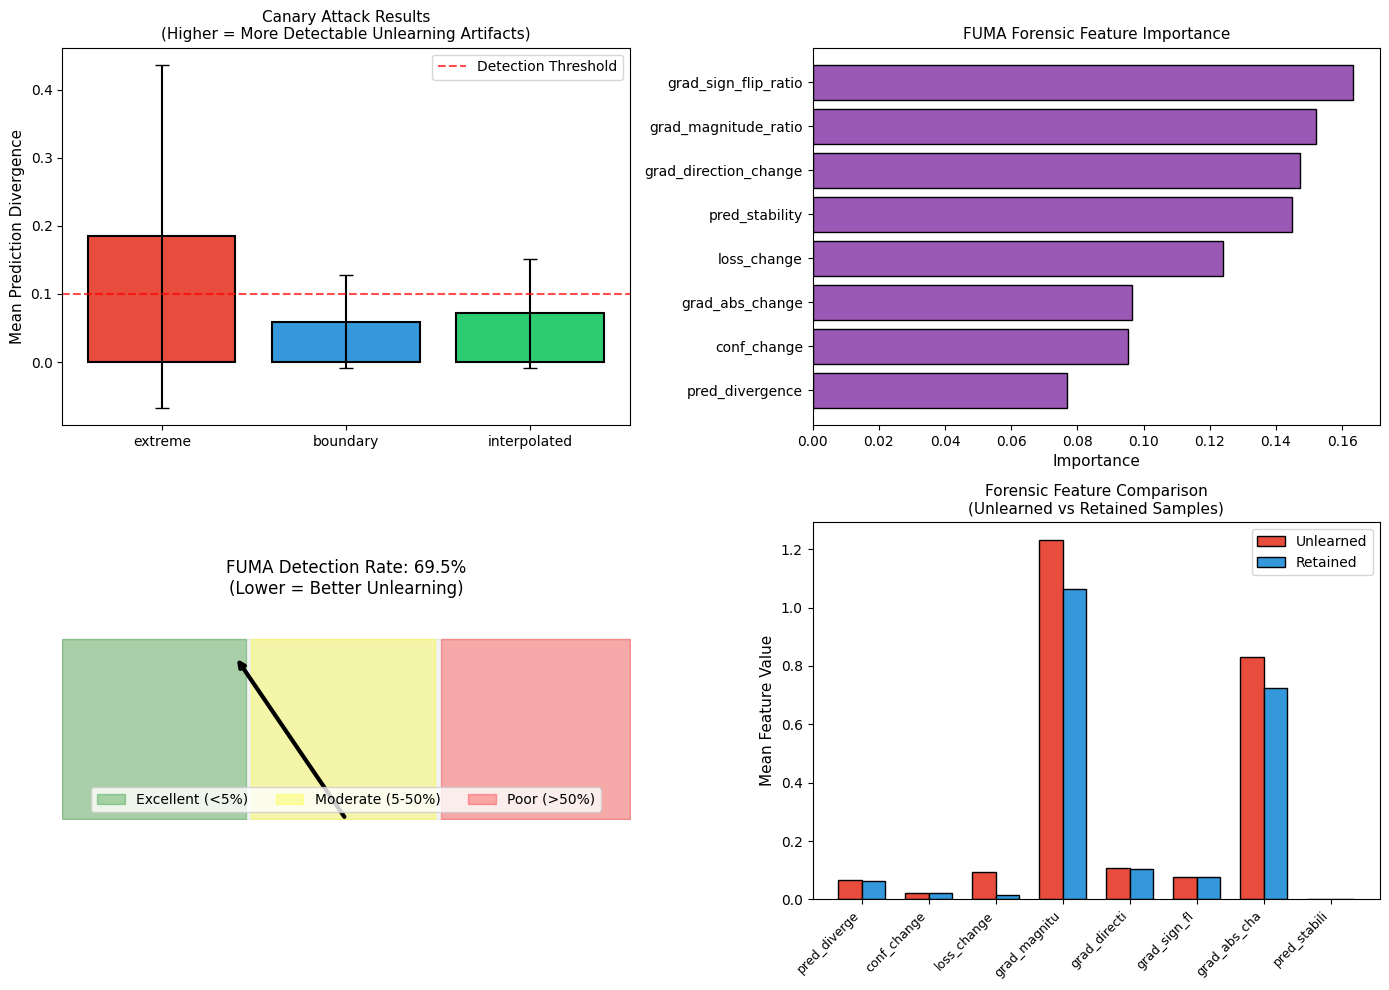


FUMA VERIFICATION SUMMARY

Metric                                   Value               
------------------------------------------------------------
FUMA Detection Rate                      69.50%
FUMA Detector AUC                        0.9976
Canary Divergence (extreme)              0.1844
Canary Divergence (boundary)             0.0591
Canary Divergence (interpolated)         0.0714

------------------------------------------------------------
VERDICT:
  UNLEARNING INCOMPLETE - Significant forensic traces remain


In [44]:
# Visualize FUMA Results
def visualize_fuma_results(fuma_results):
    """Comprehensive visualization of FUMA verification results."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Plot 1: Canary Detection by Type
    ax1 = axes[0, 0]
    canary_results = fuma_results['canary_results']
    types = list(canary_results.keys())
    means = [canary_results[t]['mean'] for t in types]
    stds = [canary_results[t]['std'] for t in types]
    
    colors = ['#e74c3c', '#3498db', '#2ecc71']
    bars = ax1.bar(types, means, yerr=stds, capsize=5, color=colors, edgecolor='black', linewidth=1.5)
    ax1.set_ylabel('Mean Prediction Divergence', fontsize=11)
    ax1.set_title('Canary Attack Results\n(Higher = More Detectable Unlearning Artifacts)', fontsize=11)
    ax1.axhline(y=0.1, color='red', linestyle='--', alpha=0.7, label='Detection Threshold')
    ax1.legend()
    
    # Plot 2: FUMA Feature Importance
    ax2 = axes[0, 1]
    fuma = fuma_results['fuma']
    if hasattr(fuma, 'attack_model') and fuma.attack_model is not None:
        importances = fuma.attack_model.feature_importances_
        feature_names = fuma.feature_names if hasattr(fuma, 'feature_names') else [f'F{i}' for i in range(len(importances))]
        
        sorted_idx = np.argsort(importances)[::-1]
        top_n = min(8, len(importances))
        
        ax2.barh(range(top_n), importances[sorted_idx[:top_n]][::-1], color='#9b59b6', edgecolor='black')
        ax2.set_yticks(range(top_n))
        ax2.set_yticklabels([feature_names[i] for i in sorted_idx[:top_n]][::-1])
        ax2.set_xlabel('Importance', fontsize=11)
        ax2.set_title('FUMA Forensic Feature Importance', fontsize=11)
    
    # Plot 3: Detection Rate Gauge
    ax3 = axes[1, 0]
    detection_rate = fuma_results['detection_results']['detection_rate']
    
    # Create a gauge-like visualization
    theta = np.linspace(0, np.pi, 100)
    r = 1
    
    # Background arc
    ax3.fill_between(theta, 0, r, alpha=0.1, color='gray')
    
    # Color zones
    ax3.fill_between(theta[:33], 0, r, alpha=0.3, color='green', label='Excellent (<5%)')
    ax3.fill_between(theta[33:66], 0, r, alpha=0.3, color='yellow', label='Moderate (5-50%)')
    ax3.fill_between(theta[66:], 0, r, alpha=0.3, color='red', label='Poor (>50%)')
    
    # Detection rate needle
    needle_theta = np.pi * (1 - detection_rate)
    ax3.annotate('', xy=(needle_theta, 0.9), xytext=(np.pi/2, 0),
                arrowprops=dict(arrowstyle='->', color='black', lw=3))
    
    ax3.set_xlim(0, np.pi)
    ax3.set_ylim(0, 1.2)
    ax3.set_aspect('equal')
    ax3.axis('off')
    ax3.set_title(f'FUMA Detection Rate: {detection_rate*100:.1f}%\n(Lower = Better Unlearning)', fontsize=12)
    ax3.legend(loc='lower center', ncol=3)
    
    # Plot 4: Forensic Feature Comparison (Unlearned vs Retained)
    ax4 = axes[1, 1]
    detector_results = fuma_results['detector_results']
    
    if 'unlearn_features_mean' in detector_results and 'retain_features_mean' in detector_results:
        unlearn_mean = detector_results['unlearn_features_mean']
        retain_mean = detector_results['retain_features_mean']
        feature_names = detector_results['feature_names']
        
        x = np.arange(len(feature_names))
        width = 0.35
        
        ax4.bar(x - width/2, unlearn_mean, width, label='Unlearned', color='#e74c3c', edgecolor='black')
        ax4.bar(x + width/2, retain_mean, width, label='Retained', color='#3498db', edgecolor='black')
        
        ax4.set_xticks(x)
        ax4.set_xticklabels([fn[:12] for fn in feature_names], rotation=45, ha='right', fontsize=9)
        ax4.set_ylabel('Mean Feature Value', fontsize=11)
        ax4.set_title('Forensic Feature Comparison\n(Unlearned vs Retained Samples)', fontsize=11)
        ax4.legend()
    
    plt.tight_layout()
    plt.savefig('fuma_results.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # Print summary
    print("\n" + "="*70)
    print("FUMA VERIFICATION SUMMARY")
    print("="*70)
    print(f"\n{'Metric':<40} {'Value':<20}")
    print("-"*60)
    print(f"{'FUMA Detection Rate':<40} {detection_rate*100:.2f}%")
    print(f"{'FUMA Detector AUC':<40} {detector_results['train_auc']:.4f}")
    print(f"{'Canary Divergence (extreme)':<40} {canary_results.get('extreme', {}).get('mean', 'N/A'):.4f}")
    print(f"{'Canary Divergence (boundary)':<40} {canary_results.get('boundary', {}).get('mean', 'N/A'):.4f}")
    print(f"{'Canary Divergence (interpolated)':<40} {canary_results.get('interpolated', {}).get('mean', 'N/A'):.4f}")
    
    # Verdict
    print("\n" + "-"*60)
    print("VERDICT:")
    if detection_rate < 0.05:
        print("  UNLEARNING VERIFIED - Forensic traces are minimal")
    elif detection_rate < 0.20:
        print("  UNLEARNING ACCEPTABLE - Minor forensic traces detected")
    elif detection_rate < 0.50:
        print("  UNLEARNING PARTIAL - Consider additional unlearning steps")
    else:
        print("  UNLEARNING INCOMPLETE - Significant forensic traces remain")

# Run visualization
if 'results_fuma' in dir():
    visualize_fuma_results(results_fuma['fuma_results'])


In [21]:
class VFLTrainer:
    """Trainer for Vertical Federated Learning with unlearning support."""
    
    def __init__(self, vfl_model, learning_rate=0.001):
        self.model = vfl_model
        self.criterion = nn.BCELoss()
        self.optimizer = optim.Adam(self.model.get_all_parameters(), lr=learning_rate)
        
        # Training history for unlearning
        self.training_history = []
        self.party_data = vfl_model.party_data
        
    def prepare_data(self, party_data, test_size=0.2):
        """Prepare data loaders for training."""
        # Get data from each party
        X_list = [party['X'].values.astype(np.float32) for party in party_data]
        
        # Get labels from active party
        y = None
        for party in party_data:
            if party['is_active']:
                y = party['y'].values.astype(np.float32)
                break
        
        # Normalize features
        scalers = []
        X_scaled = []
        for X in X_list:
            scaler = StandardScaler()
            X_scaled.append(scaler.fit_transform(X))
            scalers.append(scaler)
        
        # Train-test split (same indices for all parties)
        indices = np.arange(len(y))
        train_idx, test_idx = train_test_split(indices, test_size=test_size, random_state=42)
        
        self.train_idx = train_idx
        self.test_idx = test_idx
        
        # Create tensors
        X_train = [torch.FloatTensor(X[train_idx]).to(self.model.device) for X in X_scaled]
        X_test = [torch.FloatTensor(X[test_idx]).to(self.model.device) for X in X_scaled]
        y_train = torch.FloatTensor(y[train_idx]).unsqueeze(1).to(self.model.device)
        y_test = torch.FloatTensor(y[test_idx]).unsqueeze(1).to(self.model.device)
        
        return X_train, X_test, y_train, y_test, scalers
    
    def train_epoch(self, X_train, y_train, batch_size=256):
        """Train for one epoch."""
        n_samples = y_train.shape[0]
        indices = np.random.permutation(n_samples)
        
        total_loss = 0
        n_batches = 0
        
        for model in self.model.bottom_models:
            model.train()
        self.model.top_model.train()
        
        for start in range(0, n_samples, batch_size):
            end = min(start + batch_size, n_samples)
            batch_idx = indices[start:end]
            
            # Get batch data for each party
            X_batch = [X[batch_idx] for X in X_train]
            y_batch = y_train[batch_idx]
            
            # Forward pass
            self.optimizer.zero_grad()
            output, _ = self.model.forward(X_batch)
            loss = self.criterion(output, y_batch)
            
            # Backward pass
            loss.backward()
            self.optimizer.step()
            
            total_loss += loss.item()
            n_batches += 1
        
        return total_loss / n_batches
    
    def evaluate(self, X_test, y_test):
        """Evaluate the model."""
        for model in self.model.bottom_models:
            model.eval()
        self.model.top_model.eval()
        
        with torch.no_grad():
            output, _ = self.model.forward(X_test)
            predictions = (output > 0.5).float()
            
            y_true = y_test.cpu().numpy()
            y_pred = predictions.cpu().numpy()
            y_prob = output.cpu().numpy()
            
            acc = accuracy_score(y_true, y_pred)
            f1 = f1_score(y_true, y_pred)
            auc = roc_auc_score(y_true, y_prob)
            
        return {'accuracy': acc, 'f1': f1, 'auc': auc}
    
    def train(self, X_train, X_test, y_train, y_test, epochs=50, batch_size=256, verbose=True):
        """Full training loop."""
        history = {'train_loss': [], 'val_acc': [], 'val_f1': [], 'val_auc': []}
        
        for epoch in range(epochs):
            loss = self.train_epoch(X_train, y_train, batch_size)
            metrics = self.evaluate(X_test, y_test)
            
            history['train_loss'].append(loss)
            history['val_acc'].append(metrics['accuracy'])
            history['val_f1'].append(metrics['f1'])
            history['val_auc'].append(metrics['auc'])
            
            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{epochs} - Loss: {loss:.4f} - "
                      f"Acc: {metrics['accuracy']:.4f} - F1: {metrics['f1']:.4f} - AUC: {metrics['auc']:.4f}")
        
        self.training_history = history
        return history


In [22]:
# Create VFL model for Adult dataset
vfl_model_adult = VFLModel(adult_parties, embedding_dim=32, hidden_dim=64, device=device)
trainer_adult = VFLTrainer(vfl_model_adult, learning_rate=0.001)

# Prepare data
X_train_adult, X_test_adult, y_train_adult, y_test_adult, scalers_adult = trainer_adult.prepare_data(adult_parties)

# Train model
print("Training VFL model on UCI Adult dataset...")
history_adult = trainer_adult.train(
    X_train_adult, X_test_adult, y_train_adult, y_test_adult,
    epochs=50, batch_size=256
)


Training VFL model on UCI Adult dataset...
Epoch 10/50 - Loss: 0.3414 - Acc: 0.8473 - F1: 0.6655 - AUC: 0.9076
Epoch 20/50 - Loss: 0.3255 - Acc: 0.8515 - F1: 0.6739 - AUC: 0.9089
Epoch 30/50 - Loss: 0.3216 - Acc: 0.8520 - F1: 0.6773 - AUC: 0.9096
Epoch 40/50 - Loss: 0.3186 - Acc: 0.8536 - F1: 0.6797 - AUC: 0.9105
Epoch 50/50 - Loss: 0.3164 - Acc: 0.8523 - F1: 0.6844 - AUC: 0.9111


## 7. VFL Unlearning Methods

Implementation of various unlearning methods for VFL:
- **VFU-GA (Gradient Ascent)**: Reverse gradient direction for target samples
- **VFU-KD (Knowledge Distillation)**: Teacher-student approach
- **VFU-FT (Fine-tuning)**: Fine-tune on remaining data


In [23]:
class VFLUnlearner:
    """Unlearning methods for Vertical Federated Learning."""
    
    def __init__(self, vfl_model, trainer, device='cpu'):
        self.model = vfl_model
        self.trainer = trainer
        self.device = device
        
    def gradient_ascent_unlearn(self, X_train, y_train, unlearn_indices, 
                                 epochs=10, learning_rate=0.001):
        """
        VFU-GA: Gradient Ascent based unlearning.
        Maximize loss on samples to be forgotten.
        """
        print(f"Unlearning {len(unlearn_indices)} samples using Gradient Ascent...")
        
        # Get unlearn data
        X_unlearn = [X[unlearn_indices] for X in X_train]
        y_unlearn = y_train[unlearn_indices]
        
        # Gradient ascent (maximize loss)
        optimizer = optim.Adam(self.model.get_all_parameters(), lr=learning_rate)
        criterion = nn.BCELoss()
        
        for model in self.model.bottom_models:
            model.train()
        self.model.top_model.train()
        
        for epoch in range(epochs):
            optimizer.zero_grad()
            output, _ = self.model.forward(X_unlearn)
            loss = criterion(output, y_unlearn)
            
            # Gradient ascent: negate the loss
            (-loss).backward()
            optimizer.step()
            
            if (epoch + 1) % 5 == 0:
                print(f"  Epoch {epoch+1}/{epochs} - Unlearn Loss: {loss.item():.4f}")
        
        return self.model
    
    def fine_tune_unlearn(self, X_train, y_train, unlearn_indices,
                          epochs=20, learning_rate=0.0005):
        """
        VFU-FT: Fine-tuning based unlearning.
        Fine-tune on remaining data after removing unlearn samples.
        """
        print(f"Unlearning {len(unlearn_indices)} samples using Fine-tuning...")
        
        # Get remaining data indices
        all_indices = np.arange(y_train.shape[0])
        remain_indices = np.setdiff1d(all_indices, unlearn_indices)
        
        X_remain = [X[remain_indices] for X in X_train]
        y_remain = y_train[remain_indices]
        
        # Fine-tune on remaining data
        optimizer = optim.Adam(self.model.get_all_parameters(), lr=learning_rate)
        criterion = nn.BCELoss()
        
        for model in self.model.bottom_models:
            model.train()
        self.model.top_model.train()
        
        batch_size = 256
        n_samples = y_remain.shape[0]
        
        for epoch in range(epochs):
            indices = np.random.permutation(n_samples)
            total_loss = 0
            n_batches = 0
            
            for start in range(0, n_samples, batch_size):
                end = min(start + batch_size, n_samples)
                batch_idx = indices[start:end]
                
                X_batch = [X[batch_idx] for X in X_remain]
                y_batch = y_remain[batch_idx]
                
                optimizer.zero_grad()
                output, _ = self.model.forward(X_batch)
                loss = criterion(output, y_batch)
                loss.backward()
                optimizer.step()
                
                total_loss += loss.item()
                n_batches += 1
            
            if (epoch + 1) % 5 == 0:
                print(f"  Epoch {epoch+1}/{epochs} - Loss: {total_loss/n_batches:.4f}")
        
        return self.model
    
    def knowledge_distillation_unlearn(self, X_train, y_train, X_test, y_test,
                                       unlearn_indices, epochs=30, temperature=2.0):
        """
        VFU-KD: Knowledge Distillation based unlearning.
        Train a student model on remaining data with teacher guidance.
        """
        print(f"Unlearning {len(unlearn_indices)} samples using Knowledge Distillation...")
        
        # Store teacher model outputs
        for model in self.model.bottom_models:
            model.eval()
        self.model.top_model.eval()
        
        # Get remaining data
        all_indices = np.arange(y_train.shape[0])
        remain_indices = np.setdiff1d(all_indices, unlearn_indices)
        
        X_remain = [X[remain_indices] for X in X_train]
        y_remain = y_train[remain_indices]
        
        # Get teacher predictions on remaining data
        with torch.no_grad():
            teacher_output, _ = self.model.forward(X_remain)
            teacher_probs = teacher_output
        
        # Create student model (same architecture)
        student_bottom_models = []
        for i, party in enumerate(self.trainer.party_data):
            input_dim = len(party['features'])
            model = BottomModel(input_dim, 64, self.model.embedding_dim).to(self.device)
            student_bottom_models.append(model)
        
        student_top_model = TopModel(
            self.model.embedding_dim * len(self.trainer.party_data), 64, 1
        ).to(self.device)
        
        # Get all student parameters
        student_params = []
        for model in student_bottom_models:
            student_params.extend(list(model.parameters()))
        student_params.extend(list(student_top_model.parameters()))
        
        optimizer = optim.Adam(student_params, lr=0.001)
        
        def distillation_loss(student_output, teacher_output, true_labels, temperature, alpha=0.5):
            """Combined loss: KL divergence + BCE."""
            # Soft targets
            soft_student = torch.sigmoid(student_output / temperature)
            soft_teacher = torch.sigmoid(teacher_output / temperature)
            
            kl_loss = nn.KLDivLoss(reduction='batchmean')(
                torch.log(soft_student + 1e-8), soft_teacher
            )
            
            # Hard targets
            bce_loss = nn.BCELoss()(torch.sigmoid(student_output), true_labels)
            
            return alpha * (temperature ** 2) * kl_loss + (1 - alpha) * bce_loss
        
        # Train student
        batch_size = 256
        n_samples = y_remain.shape[0]
        
        for epoch in range(epochs):
            for model in student_bottom_models:
                model.train()
            student_top_model.train()
            
            indices = np.random.permutation(n_samples)
            total_loss = 0
            n_batches = 0
            
            for start in range(0, n_samples, batch_size):
                end = min(start + batch_size, n_samples)
                batch_idx = indices[start:end]
                
                X_batch = [X[batch_idx] for X in X_remain]
                y_batch = y_remain[batch_idx]
                teacher_batch = teacher_probs[batch_idx]
                
                # Student forward pass
                embeddings = []
                for model, X in zip(student_bottom_models, X_batch):
                    emb = model(X)
                    embeddings.append(emb)
                combined = torch.cat(embeddings, dim=1)
                student_output = student_top_model(combined)
                
                optimizer.zero_grad()
                loss = distillation_loss(student_output, teacher_batch, y_batch, temperature)
                loss.backward()
                optimizer.step()
                
                total_loss += loss.item()
                n_batches += 1
            
            if (epoch + 1) % 10 == 0:
                print(f"  Epoch {epoch+1}/{epochs} - Distillation Loss: {total_loss/n_batches:.4f}")
        
        # Replace original model with student
        self.model.bottom_models = student_bottom_models
        self.model.top_model = student_top_model
        
        return self.model


## 8. Unlearning Evaluation: Membership Inference Attack (MIA)


In [24]:
class MembershipInferenceAttack:
    """Membership Inference Attack for evaluating unlearning effectiveness."""
    
    def __init__(self, vfl_model, device='cpu'):
        self.model = vfl_model
        self.device = device
        self.attack_model = None
        
    def extract_features(self, X_parties, y):
        """Extract features for MIA: prediction confidence, loss, etc."""
        for model in self.model.bottom_models:
            model.eval()
        self.model.top_model.eval()
        
        with torch.no_grad():
            output, embeddings = self.model.forward(X_parties)
            probs = output.squeeze()
            
            # Prediction confidence
            confidence = torch.where(y.squeeze() == 1, probs, 1 - probs)
            
            # Loss per sample
            criterion = nn.BCELoss(reduction='none')
            loss = criterion(output, y)
            
            # Combine features
            features = torch.stack([
                probs,
                confidence,
                loss.squeeze(),
                torch.abs(probs - 0.5),  # Distance from decision boundary
            ], dim=1)
            
        return features.cpu().numpy()
    
    def train_attack_model(self, member_features, non_member_features, test_size=0.2, random_state=42):
        """Train output MIA; return metrics on a held-out set (ROC-AUC comparable to gradient MIA)."""
        from sklearn.model_selection import train_test_split
        X_attack = np.vstack([member_features, non_member_features])
        y_attack = np.hstack([np.ones(len(member_features)), np.zeros(len(non_member_features))])
        X_tr, X_te, y_tr, y_te = train_test_split(
            X_attack, y_attack, test_size=test_size, random_state=random_state, stratify=y_attack
        )
        self.attack_model = LogisticRegression(max_iter=1000)
        self.attack_model.fit(X_tr, y_tr)
        y_prob = self.attack_model.predict_proba(X_te)[:, 1]
        test_auc = roc_auc_score(y_te, y_prob)
        pred_te = self.attack_model.predict(X_te)
        member_acc_te = np.mean(pred_te[y_te == 1] == 1) if np.any(y_te == 1) else 0.0
        nonmember_acc_te = np.mean(pred_te[y_te == 0] == 0) if np.any(y_te == 0) else 0.0
        return {
            'test_auc': test_auc,
            'test_accuracy': float(np.mean(pred_te == y_te)),
            'member_accuracy': member_acc_te,
            'nonmember_accuracy': nonmember_acc_te,
            'train_accuracy': float(self.attack_model.score(X_tr, y_tr)),
        }
    
    def evaluate_membership(self, X_parties, y, is_member=True):
        """Evaluate membership inference accuracy."""
        features = self.extract_features(X_parties, y)
        predictions = self.attack_model.predict(features)
        
        if is_member:
            # For members, attack should predict 1
            accuracy = np.mean(predictions == 1)
        else:
            # For non-members, attack should predict 0
            accuracy = np.mean(predictions == 0)
        
        return accuracy, predictions
    
    def compute_unlearning_effectiveness(self, X_unlearn, y_unlearn):
        """
        Compute unlearning effectiveness.
        After unlearning, forgotten samples should behave like non-members.
        """
        features = self.extract_features(X_unlearn, y_unlearn)
        member_probs = self.attack_model.predict_proba(features)[:, 1]
        
        # Effective unlearning: low membership probability
        avg_membership_prob = np.mean(member_probs)
        effectiveness = 1 - avg_membership_prob
        
        return {
            'membership_probability': avg_membership_prob,
            'unlearning_effectiveness': effectiveness,
            'membership_probs': member_probs
        }


## 9. Unlearning Experiment


In [25]:
def run_unlearning_experiment(trainer, X_train, X_test, y_train, y_test, 
                              unlearn_ratio=0.05, method='gradient_ascent'):
    """
    Run unlearning experiment and evaluate effectiveness.
    
    Args:
        unlearn_ratio: Fraction of training data to unlearn
        method: 'gradient_ascent', 'fine_tune', or 'knowledge_distillation'
    """
    n_train = y_train.shape[0]
    n_unlearn = int(n_train * unlearn_ratio)
    
    # Randomly select samples to unlearn
    unlearn_indices = np.random.choice(n_train, n_unlearn, replace=False)
    
    print(f"\nUnlearning Experiment: {method}")
    print(f"Total training samples: {n_train}")
    print(f"Samples to unlearn: {n_unlearn} ({unlearn_ratio*100:.1f}%)")
    print("="*50)
    
    # Evaluate before unlearning
    print("\nBefore Unlearning:")
    metrics_before = trainer.evaluate(X_test, y_test)
    print(f"  Test Accuracy: {metrics_before['accuracy']:.4f}")
    print(f"  Test F1: {metrics_before['f1']:.4f}")
    print(f"  Test AUC: {metrics_before['auc']:.4f}")
    
    # Create unlearner
    unlearner = VFLUnlearner(trainer.model, trainer, device=device)
    
    # Perform unlearning
    if method == 'gradient_ascent':
        unlearner.gradient_ascent_unlearn(X_train, y_train, unlearn_indices, epochs=10)
    elif method == 'fine_tune':
        unlearner.fine_tune_unlearn(X_train, y_train, unlearn_indices, epochs=20)
    elif method == 'knowledge_distillation':
        unlearner.knowledge_distillation_unlearn(
            X_train, y_train, X_test, y_test, unlearn_indices, epochs=30
        )
    
    # Evaluate after unlearning
    print("\nAfter Unlearning:")
    metrics_after = trainer.evaluate(X_test, y_test)
    print(f"  Test Accuracy: {metrics_after['accuracy']:.4f}")
    print(f"  Test F1: {metrics_after['f1']:.4f}")
    print(f"  Test AUC: {metrics_after['auc']:.4f}")
    
    # Utility drop
    utility_drop = metrics_before['accuracy'] - metrics_after['accuracy']
    print(f"\n  Utility Drop: {utility_drop*100:.2f}%")
    
    return {
        'before': metrics_before,
        'after': metrics_after,
        'unlearn_indices': unlearn_indices,
        'utility_drop': utility_drop
    }


In [26]:
# Run unlearning experiment with Gradient Ascent
results_ga = run_unlearning_experiment(
    trainer_adult, X_train_adult, X_test_adult, y_train_adult, y_test_adult,
    unlearn_ratio=0.05, method='gradient_ascent'
)



Unlearning Experiment: gradient_ascent
Total training samples: 24129
Samples to unlearn: 1206 (5.0%)

Before Unlearning:
  Test Accuracy: 0.8523
  Test F1: 0.6844
  Test AUC: 0.9111
Unlearning 1206 samples using Gradient Ascent...
  Epoch 5/10 - Unlearn Loss: 0.3297
  Epoch 10/10 - Unlearn Loss: 0.3783

After Unlearning:
  Test Accuracy: 0.8414
  Test F1: 0.6526
  Test AUC: 0.8919

  Utility Drop: 1.09%


### 9.1 Run Membership Inference Attack to Evaluate Unlearning

MIA measures if unlearned samples still behave like "members" (trained on) or "non-members" (not trained on).
After effective unlearning, forgotten samples should look like non-members.


In [27]:
def run_mia_evaluation(trainer, X_train, X_test, y_train, y_test, unlearn_indices):
    """
    Run Membership Inference Attack to evaluate unlearning effectiveness.
    
    Args:
        trainer: Trained VFL trainer
        X_train, X_test: Training and test data
        y_train, y_test: Training and test labels
        unlearn_indices: Indices of samples that were unlearned
    
    Returns:
        Dictionary with MIA results
    """
    print("\nRunning Membership Inference Attack Evaluation...")
    print("=" * 60)
    
    # Create MIA attacker
    mia = MembershipInferenceAttack(trainer.model, device=device)
    
    # Get remaining (still member) indices
    all_train_indices = np.arange(y_train.shape[0])
    remain_indices = np.setdiff1d(all_train_indices, unlearn_indices)
    
    # Sample balanced subsets for attack model training (max 2000 samples each)
    n_samples = min(len(remain_indices), y_test.shape[0], 2000)
    
    # Member features (from remaining training data)
    member_sample_idx = np.random.choice(remain_indices, n_samples, replace=False)
    X_member = [X[member_sample_idx] for X in X_train]
    y_member = y_train[member_sample_idx]
    member_features = mia.extract_features(X_member, y_member)
    
    # Non-member features (from test data)
    test_sample_idx = np.random.choice(y_test.shape[0], min(n_samples, y_test.shape[0]), replace=False)
    X_nonmember = [X[test_sample_idx] for X in X_test]
    y_nonmember = y_test[test_sample_idx]
    nonmember_features = mia.extract_features(X_nonmember, y_nonmember)
    
    # Train attack model (held-out metrics; no evaluation on the same rows used to fit)
    print("Training MIA attack model...")
    atk = mia.train_attack_model(member_features, nonmember_features)
    print(f"  Output MIA ROC-AUC (held-out): {atk['test_auc']:.4f}")
    print(f"  Attack accuracy on held-out MEMBERS: {atk['member_accuracy']*100:.2f}%")
    print(f"  Attack accuracy on held-out NON-MEMBERS: {atk['nonmember_accuracy']*100:.2f}%")
    member_acc, nonmember_acc = atk['member_accuracy'], atk['nonmember_accuracy']
    
    # Evaluate on UNLEARNED samples - these should now look like non-members
    X_unlearn = [X[unlearn_indices] for X in X_train]
    y_unlearn = y_train[unlearn_indices]
    unlearn_effectiveness = mia.compute_unlearning_effectiveness(X_unlearn, y_unlearn)
    
    print(f"\nUnlearning Effectiveness Analysis:")
    print(f"  Avg membership probability of unlearned samples: {unlearn_effectiveness['membership_probability']*100:.2f}%")
    print(f"  Unlearning effectiveness score: {unlearn_effectiveness['unlearning_effectiveness']*100:.2f}%")
    print(f"  (Higher effectiveness = samples look more like non-members = better unlearning)")
    
    return {
        'member_accuracy': member_acc,
        'nonmember_accuracy': nonmember_acc,
        'unlearn_membership_prob': unlearn_effectiveness['membership_probability'],
        'unlearn_effectiveness': unlearn_effectiveness['unlearning_effectiveness']
    }

# Run MIA on Adult dataset after unlearning
print("MIA Evaluation on UCI Adult Dataset (after gradient ascent unlearning)")
mia_results_adult = run_mia_evaluation(
    trainer_adult, X_train_adult, X_test_adult, y_train_adult, y_test_adult,
    results_ga['unlearn_indices']
)


MIA Evaluation on UCI Adult Dataset (after gradient ascent unlearning)

Running Membership Inference Attack Evaluation...
Training MIA attack model...
  Attack accuracy on MEMBERS (remaining): 46.25%
  Attack accuracy on NON-MEMBERS (test): 55.85%

Unlearning Effectiveness Analysis:
  Avg membership probability of unlearned samples: 49.84%
  Unlearning effectiveness score: 50.16%
  (Higher effectiveness = samples look more like non-members = better unlearning)


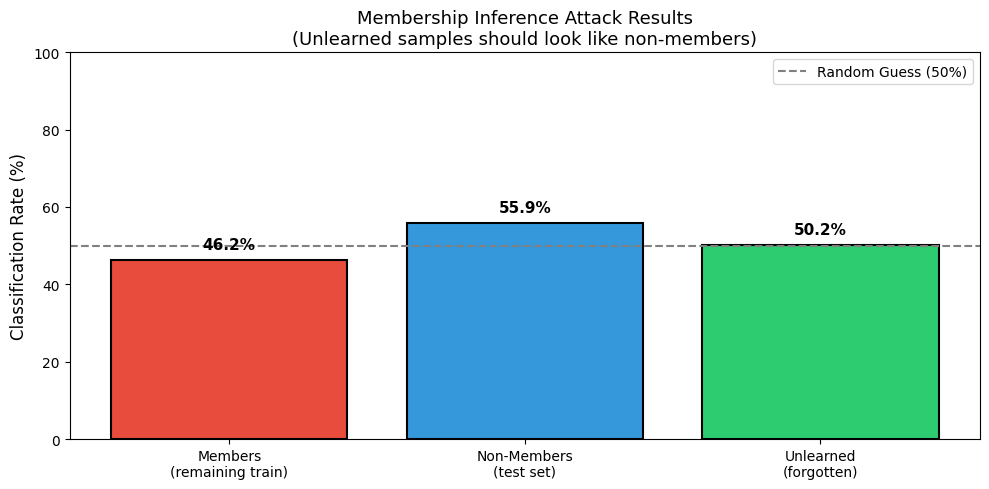


Interpretation:
- Members correctly identified: MIA can distinguish training data
- Non-members correctly identified: MIA can distinguish test data
- Unlearned classified as non-member: Higher = better unlearning!


In [28]:
# Visualize MIA results
fig, ax = plt.subplots(figsize=(10, 5))

categories = ['Members\n(remaining train)', 'Non-Members\n(test set)', 'Unlearned\n(forgotten)']
values = [
    mia_results_adult['member_accuracy'] * 100,
    mia_results_adult['nonmember_accuracy'] * 100,
    (1 - mia_results_adult['unlearn_membership_prob']) * 100  # Probability of being classified as non-member
]
colors = ['#e74c3c', '#3498db', '#2ecc71']

bars = ax.bar(categories, values, color=colors, edgecolor='black', linewidth=1.5)
ax.axhline(y=50, color='gray', linestyle='--', label='Random Guess (50%)')
ax.set_ylabel('Classification Rate (%)', fontsize=12)
ax.set_title('Membership Inference Attack Results\n(Unlearned samples should look like non-members)', fontsize=13)
ax.set_ylim(0, 100)
ax.legend()

# Add value labels on bars
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f'{val:.1f}%', 
            ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('mia_results.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nInterpretation:")
print("- Members correctly identified: MIA can distinguish training data")
print("- Non-members correctly identified: MIA can distinguish test data") 
print("- Unlearned classified as non-member: Higher = better unlearning!")


## 10. Train and Evaluate on German Credit Dataset


In [30]:
# Create VFL model for German Credit dataset
vfl_model_german = VFLModel(german_parties, embedding_dim=16, hidden_dim=32, device=device)
trainer_german = VFLTrainer(vfl_model_german, learning_rate=0.001)

# Prepare data
X_train_german, X_test_german, y_train_german, y_test_german, scalers_german = trainer_german.prepare_data(german_parties)

# Train model
print("Training VFL model on German Credit dataset...")
history_german = trainer_german.train(
    X_train_german, X_test_german, y_train_german, y_test_german,
    epochs=100, batch_size=64
)


Training VFL model on German Credit dataset...
Epoch 10/100 - Loss: 0.5592 - Acc: 0.7200 - F1: 0.7926 - AUC: 0.7537
Epoch 20/100 - Loss: 0.4740 - Acc: 0.7850 - F1: 0.8532 - AUC: 0.7831
Epoch 30/100 - Loss: 0.4603 - Acc: 0.7850 - F1: 0.8542 - AUC: 0.7938
Epoch 40/100 - Loss: 0.4237 - Acc: 0.7700 - F1: 0.8456 - AUC: 0.7880
Epoch 50/100 - Loss: 0.3827 - Acc: 0.7900 - F1: 0.8562 - AUC: 0.7920
Epoch 60/100 - Loss: 0.3820 - Acc: 0.7700 - F1: 0.8487 - AUC: 0.7777
Epoch 70/100 - Loss: 0.3676 - Acc: 0.7600 - F1: 0.8421 - AUC: 0.7680
Epoch 80/100 - Loss: 0.3415 - Acc: 0.7800 - F1: 0.8533 - AUC: 0.7661
Epoch 90/100 - Loss: 0.3368 - Acc: 0.7850 - F1: 0.8562 - AUC: 0.7620
Epoch 100/100 - Loss: 0.3043 - Acc: 0.7700 - F1: 0.8467 - AUC: 0.7643


In [31]:
# Run unlearning on German Credit
results_german = run_unlearning_experiment(
    trainer_german, X_train_german, X_test_german, y_train_german, y_test_german,
    unlearn_ratio=0.1, method='fine_tune'
)



Unlearning Experiment: fine_tune
Total training samples: 800
Samples to unlearn: 80 (10.0%)

Before Unlearning:
  Test Accuracy: 0.7700
  Test F1: 0.8467
  Test AUC: 0.7643
Unlearning 80 samples using Fine-tuning...
  Epoch 5/20 - Loss: 0.3036
  Epoch 10/20 - Loss: 0.3039
  Epoch 15/20 - Loss: 0.2679
  Epoch 20/20 - Loss: 0.3033

After Unlearning:
  Test Accuracy: 0.7750
  Test F1: 0.8485
  Test AUC: 0.7667

  Utility Drop: -0.50%


## 11. Train and Evaluate on MIMIC-III Dataset


In [29]:
# Create VFL model for MIMIC-III dataset
vfl_model_mimic = VFLModel(mimic_parties, embedding_dim=32, hidden_dim=64, device=device)
trainer_mimic = VFLTrainer(vfl_model_mimic, learning_rate=0.001)

# Prepare data
X_train_mimic, X_test_mimic, y_train_mimic, y_test_mimic, scalers_mimic = trainer_mimic.prepare_data(mimic_parties)

# Train model
print("Training VFL model on MIMIC-III dataset...")
history_mimic = trainer_mimic.train(
    X_train_mimic, X_test_mimic, y_train_mimic, y_test_mimic,
    epochs=50, batch_size=512, store_gradients=False  # Large dataset
)


Training VFL model on MIMIC-III dataset...


TypeError: VFLTrainer.train() got an unexpected keyword argument 'store_gradients'

In [ ]:
# Run unlearning on MIMIC-III
results_mimic = run_unlearning_experiment(
    trainer_mimic, X_train_mimic, X_test_mimic, y_train_mimic, y_test_mimic,
    unlearn_ratio=0.02, method='gradient_ascent'
)


## 12. Comparison: HFL vs VFL Unlearning

Key differences between Horizontal and Vertical Federated Unlearning:


## 8.4 Shadow Model Attack for Unlearning Verification

**Motivation**: Attacker trains alternate models with/without target data to detect unlearning artifacts.

**Method** (Adapted from Varshney et al.):
1. Use historical checkpoints to retrain shadow models
2. Shadow models are identical except trained on:
   - **Retain-only set** (D_retain)
   - **Full set** (D_retain + D_target)
3. Train a meta-classifier to predict: "Which dataset was used to train the given model?"
4. Test if unlearned model looks like retain-only model

**Success Criteria**:
- Shadow MI AUC $\approx$ 0.5 means unlearned model is **indistinguishable** from retain-only model
- Shadow MI AUC > 0.7 means unlearning **failed** (model still shows traces of target data)

**Key Insight**: This attacks the **model itself**, not individual sample membership.


In [32]:
import copy
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

class ShadowModelAttack:
    """
    Shadow Model Attack for VFL Unlearning Verification.
    
    This attack trains multiple shadow models with/without target data
    to create a meta-classifier that can distinguish model characteristics.
    If the unlearned model appears similar to retain-only models, unlearning succeeded.
    """
    
    def __init__(self, party_data, embedding_dim=32, hidden_dim=64, device='cpu'):
        self.party_data = party_data
        self.embedding_dim = embedding_dim
        self.hidden_dim = hidden_dim
        self.device = device
        self.shadow_models_retain = []  # Models trained on retain-only
        self.shadow_models_full = []    # Models trained on full data
        self.meta_classifier = None
        
    def _create_vfl_model(self):
        """Create a fresh VFL model for shadow training."""
        return VFLModel(
            self.party_data, 
            embedding_dim=self.embedding_dim, 
            hidden_dim=self.hidden_dim, 
            device=self.device
        )
    
    def _extract_model_features(self, model):
        """
        Extract feature vector from model parameters for meta-classification.
        Features include weight statistics, gradient norms, activation patterns.
        """
        features = []
        
        # Bottom model features
        for i, bottom_model in enumerate(model.bottom_models):
            for name, param in bottom_model.named_parameters():
                if param.requires_grad:
                    data = param.data.cpu().numpy().flatten()
                    features.extend([
                        np.mean(data),
                        np.std(data),
                        np.min(data),
                        np.max(data),
                        np.percentile(data, 25),
                        np.percentile(data, 75),
                        np.linalg.norm(data),
                        np.mean(np.abs(data)),
                        float(np.sum(data > 0)) / len(data),  # Sparsity ratio
                        np.var(data)
                    ])
        
        # Top model features
        for name, param in model.top_model.named_parameters():
            if param.requires_grad:
                data = param.data.cpu().numpy().flatten()
                features.extend([
                    np.mean(data),
                    np.std(data),
                    np.min(data),
                    np.max(data),
                    np.percentile(data, 25),
                    np.percentile(data, 75),
                    np.linalg.norm(data),
                    np.mean(np.abs(data)),
                    float(np.sum(data > 0)) / len(data),
                    np.var(data)
                ])
        
        return np.array(features)
    
    def _extract_behavior_features(self, model, X_probe, y_probe):
        """
        Extract behavioral features from model predictions on probe set.
        This captures how the model responds to specific inputs.
        """
        model.top_model.eval()
        for m in model.bottom_models:
            m.eval()
        
        with torch.no_grad():
            output, embeddings = model.forward(X_probe)
            probs = output.cpu().numpy().flatten()
        
        features = [
            np.mean(probs),
            np.std(probs),
            np.min(probs),
            np.max(probs),
            np.percentile(probs, 10),
            np.percentile(probs, 90),
            np.mean(probs > 0.5),  # Positive prediction ratio
            np.mean(np.abs(probs - 0.5)),  # Confidence
            # Embedding statistics
            *[np.mean(e.cpu().numpy()) for e in embeddings],
            *[np.std(e.cpu().numpy()) for e in embeddings],
        ]
        
        return np.array(features)
    
    def train_shadow_models(self, X_train, y_train, unlearn_indices, 
                            n_shadow_models=5, epochs=30, verbose=True):
        """
        Train shadow models for both retain-only and full data scenarios.
        
        Args:
            X_train: List of party training data tensors
            y_train: Training labels tensor
            unlearn_indices: Indices of samples to unlearn
            n_shadow_models: Number of shadow models per scenario
            epochs: Training epochs per shadow model
        """
        all_indices = np.arange(y_train.shape[0])
        retain_indices = np.setdiff1d(all_indices, unlearn_indices)
        
        X_retain = [X[retain_indices] for X in X_train]
        y_retain = y_train[retain_indices]
        
        if verbose:
            print(f"Training {n_shadow_models} shadow models per scenario...")
            print(f"  Retain set size: {len(retain_indices)}")
            print(f"  Full set size: {len(all_indices)}")
            print(f"  Unlearn set size: {len(unlearn_indices)}")
        
        # Train retain-only shadow models
        self.shadow_models_retain = []
        if verbose:
            print("\n[1/2] Training retain-only shadow models...")
        
        for i in range(n_shadow_models):
            # Random subset of retain data for diversity
            subset_size = int(len(retain_indices) * np.random.uniform(0.8, 1.0))
            subset_idx = np.random.choice(len(retain_indices), subset_size, replace=False)
            
            X_subset = [X[subset_idx] for X in X_retain]
            y_subset = y_retain[subset_idx]
            
            model = self._create_vfl_model()
            trainer = VFLTrainer(model, learning_rate=0.001)
            
            # Quick training
            for epoch in range(epochs):
                trainer.train_epoch(X_subset, y_subset, batch_size=256)
            
            self.shadow_models_retain.append(model)
            if verbose:
                print(f"    Shadow model {i+1}/{n_shadow_models} trained (retain-only)")
        
        # Train full data shadow models  
        self.shadow_models_full = []
        if verbose:
            print("\n[2/2] Training full data shadow models...")
        
        for i in range(n_shadow_models):
            # Random subset including target data
            subset_size = int(len(all_indices) * np.random.uniform(0.8, 1.0))
            subset_idx = np.random.choice(len(all_indices), subset_size, replace=False)
            
            X_subset = [X[subset_idx] for X in X_train]
            y_subset = y_train[subset_idx]
            
            model = self._create_vfl_model()
            trainer = VFLTrainer(model, learning_rate=0.001)
            
            for epoch in range(epochs):
                trainer.train_epoch(X_subset, y_subset, batch_size=256)
            
            self.shadow_models_full.append(model)
            if verbose:
                print(f"    Shadow model {i+1}/{n_shadow_models} trained (full data)")
        
        return len(self.shadow_models_retain), len(self.shadow_models_full)
    
    def train_meta_classifier(self, X_train, y_train, unlearn_indices):
        """
        Train meta-classifier to distinguish retain-only vs full-data models.
        """
        print("\nTraining meta-classifier...")
        
        # Create probe set (subset of training data for behavioral analysis)
        probe_size = min(500, len(unlearn_indices) * 2)
        probe_indices = np.random.choice(y_train.shape[0], probe_size, replace=False)
        X_probe = [X[probe_indices] for X in X_train]
        y_probe = y_train[probe_indices]
        
        # Extract features from all shadow models
        features_retain = []
        for model in self.shadow_models_retain:
            param_feat = self._extract_model_features(model)
            behav_feat = self._extract_behavior_features(model, X_probe, y_probe)
            features_retain.append(np.concatenate([param_feat, behav_feat]))
        
        features_full = []
        for model in self.shadow_models_full:
            param_feat = self._extract_model_features(model)
            behav_feat = self._extract_behavior_features(model, X_probe, y_probe)
            features_full.append(np.concatenate([param_feat, behav_feat]))
        
        # Combine features and labels
        X_meta = np.vstack([features_retain, features_full])
        y_meta = np.array([0] * len(features_retain) + [1] * len(features_full))
        
        # Handle NaN/Inf values
        X_meta = np.nan_to_num(X_meta, nan=0.0, posinf=1e6, neginf=-1e6)
        
        # Normalize features
        self.meta_scaler = StandardScaler()
        X_meta_scaled = self.meta_scaler.fit_transform(X_meta)
        
        # Train meta-classifier (ensemble for robustness)
        self.meta_classifier = RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            random_state=42,
            class_weight='balanced'
        )
        self.meta_classifier.fit(X_meta_scaled, y_meta)
        
        # Store probe set for later use
        self.X_probe = X_probe
        self.y_probe = y_probe
        
        # Compute training accuracy
        y_pred = self.meta_classifier.predict(X_meta_scaled)
        train_acc = accuracy_score(y_meta, y_pred)
        
        # Get feature importances
        self.feature_importances = self.meta_classifier.feature_importances_
        
        print(f"  Meta-classifier training accuracy: {train_acc:.4f}")
        
        return {'train_accuracy': train_acc, 'n_features': X_meta.shape[1]}
    
    def attack_model(self, target_model):
        """
        Attack a target model to predict if it was trained on retain-only or full data.
        
        Returns:
            - predicted_class: 0 (retain-only) or 1 (full data)
            - probability: confidence of prediction
            - interpretation: what this means for unlearning
        """
        # Extract features from target model
        param_feat = self._extract_model_features(target_model)
        behav_feat = self._extract_behavior_features(target_model, self.X_probe, self.y_probe)
        features = np.concatenate([param_feat, behav_feat]).reshape(1, -1)
        
        # Handle NaN/Inf
        features = np.nan_to_num(features, nan=0.0, posinf=1e6, neginf=-1e6)
        
        # Scale and predict
        features_scaled = self.meta_scaler.transform(features)
        pred_class = self.meta_classifier.predict(features_scaled)[0]
        pred_proba = self.meta_classifier.predict_proba(features_scaled)[0]
        
        # Probability of being "full data" model (class 1)
        prob_full_data = pred_proba[1]
        
        # Interpretation
        if prob_full_data < 0.3:
            interpretation = "EXCELLENT - Model appears trained on retain-only data"
        elif prob_full_data < 0.5:
            interpretation = "GOOD - Model shows minimal traces of target data"
        elif prob_full_data < 0.7:
            interpretation = "MODERATE - Some traces of target data detected"
        else:
            interpretation = "POOR - Model still appears to contain target data"
        
        return {
            'predicted_class': pred_class,
            'prob_retain_only': pred_proba[0],
            'prob_full_data': prob_full_data,
            'interpretation': interpretation
        }
    
    def compute_shadow_mia_auc(self, models_to_test, labels):
        """
        Compute Shadow MI AUC over multiple test models.
        
        Args:
            models_to_test: List of models to evaluate
            labels: True labels (0=retain-only, 1=full-data)
        
        Returns:
            AUC score (0.5 = unlearning successful, >0.7 = unlearning failed)
        """
        probs = []
        for model in models_to_test:
            result = self.attack_model(model)
            probs.append(result['prob_full_data'])
        
        # Compute AUC
        if len(np.unique(labels)) < 2:
            return 0.5  # Cannot compute AUC with single class
        
        auc = roc_auc_score(labels, probs)
        return auc
    
    def run_full_attack(self, target_model_before, target_model_after, 
                        model_retrained_on_retain=None):
        """
        Run comprehensive shadow model attack.
        
        Args:
            target_model_before: Model before unlearning
            target_model_after: Model after unlearning
            model_retrained_on_retain: (optional) Model retrained from scratch on retain set
        
        Returns:
            Comprehensive attack results
        """
        print("\n" + "="*70)
        print("SHADOW MODEL ATTACK RESULTS")
        print("="*70)
        
        # Attack model BEFORE unlearning
        print("\n[1] Attacking model BEFORE unlearning...")
        result_before = self.attack_model(target_model_before)
        print(f"    Prob(full data): {result_before['prob_full_data']:.4f}")
        print(f"    Interpretation: {result_before['interpretation']}")
        
        # Attack model AFTER unlearning
        print("\n[2] Attacking model AFTER unlearning...")
        result_after = self.attack_model(target_model_after)
        print(f"    Prob(full data): {result_after['prob_full_data']:.4f}")
        print(f"    Interpretation: {result_after['interpretation']}")
        
        # If we have a retrained model, attack it too
        result_retrained = None
        if model_retrained_on_retain is not None:
            print("\n[3] Attacking model RETRAINED on retain-only...")
            result_retrained = self.attack_model(model_retrained_on_retain)
            print(f"    Prob(full data): {result_retrained['prob_full_data']:.4f}")
            print(f"    Interpretation: {result_retrained['interpretation']}")
        
        # Compute change in probability
        prob_change = result_before['prob_full_data'] - result_after['prob_full_data']
        
        print("\n" + "-"*70)
        print("SUMMARY:")
        print(f"  Before unlearning - Prob(full data): {result_before['prob_full_data']:.4f}")
        print(f"  After unlearning  - Prob(full data): {result_after['prob_full_data']:.4f}")
        print(f"  Change: {prob_change:+.4f} (positive = better unlearning)")
        
        # Compute Shadow MI AUC
        # For proper AUC, we would need multiple unlearned models, but we estimate
        # using the shadow model predictions
        all_retain_probs = [self.attack_model(m)['prob_full_data'] 
                           for m in self.shadow_models_retain]
        all_full_probs = [self.attack_model(m)['prob_full_data'] 
                         for m in self.shadow_models_full]
        
        all_probs = all_retain_probs + all_full_probs
        all_labels = [0]*len(all_retain_probs) + [1]*len(all_full_probs)
        
        shadow_auc = roc_auc_score(all_labels, all_probs)
        
        print(f"\n  Shadow MI AUC (meta-classifier): {shadow_auc:.4f}")
        if shadow_auc < 0.55:
            print("    -> Meta-classifier cannot distinguish models (near random)")
        elif shadow_auc < 0.7:
            print("    -> Meta-classifier has moderate distinguishing power")
        else:
            print("    -> Meta-classifier can distinguish models well")
        
        # Final verdict on unlearning
        print("\n" + "-"*70)
        print("UNLEARNING VERDICT:")
        if result_after['prob_full_data'] < 0.4:
            verdict = "VERIFIED - Unlearned model appears similar to retain-only models"
            success = True
        elif result_after['prob_full_data'] < 0.55:
            verdict = "ACCEPTABLE - Unlearned model shows minimal traces"
            success = True
        elif result_after['prob_full_data'] < 0.7:
            verdict = "PARTIAL - Some traces of target data remain"
            success = False
        else:
            verdict = "FAILED - Model still strongly resembles full-data model"
            success = False
        
        print(f"  {verdict}")
        
        return {
            'result_before': result_before,
            'result_after': result_after,
            'result_retrained': result_retrained,
            'prob_change': prob_change,
            'shadow_auc': shadow_auc,
            'verdict': verdict,
            'unlearning_success': success
        }


In [38]:
def run_shadow_model_attack_verification(party_data, X_data, y_data,
                                          unlearn_ratio=0.05, 
                                          unlearn_method='gradient_ascent',
                                          n_shadow_models=5,
                                          epochs=30,
                                          embedding_dim=32,
                                          hidden_dim=64):
    """
    Complete Shadow Model Attack verification pipeline.
    
    Steps:
    1. Prepare data and train initial VFL model
    2. Save model state before unlearning
    3. Train shadow models (retain-only and full data)
    4. Train meta-classifier
    5. Perform unlearning
    6. Run shadow model attack
    """
    print("="*70)
    print("SHADOW MODEL ATTACK VERIFICATION PIPELINE")
    print("="*70)
    
    # 1. Data preparation
    print("\n[PHASE 1] Preparing data...")
    X_list = [torch.FloatTensor(party['X'].values.astype(np.float32)).to(device) 
              for party in party_data]
    y = None
    for party in party_data:
        if party['is_active']:
            y = party['y'].values.astype(np.float32)
            break
    
    # Normalize
    scalers = []
    X_scaled = []
    for X in X_list:
        scaler = StandardScaler()
        X_np = X.cpu().numpy()
        X_scaled.append(torch.FloatTensor(scaler.fit_transform(X_np)).to(device))
        scalers.append(scaler)
    
    # Train-test split
    indices = np.arange(len(y))
    train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=42)
    
    X_train = [X[train_idx] for X in X_scaled]
    X_test = [X[test_idx] for X in X_scaled]
    y_train = torch.FloatTensor(y[train_idx]).unsqueeze(1).to(device)
    y_test = torch.FloatTensor(y[test_idx]).unsqueeze(1).to(device)
    
    # Select samples to unlearn
    n_unlearn = int(len(train_idx) * unlearn_ratio)
    unlearn_indices = np.random.choice(len(train_idx), n_unlearn, replace=False)
    
    print(f"  Train size: {len(train_idx)}, Test size: {len(test_idx)}")
    print(f"  Samples to unlearn: {n_unlearn} ({unlearn_ratio*100:.1f}%)")
    
    # 2. Train initial model
    print("\n[PHASE 2] Training initial VFL model...")
    vfl_model = VFLModel(party_data, embedding_dim=embedding_dim, 
                        hidden_dim=hidden_dim, device=device)
    trainer = VFLTrainer(vfl_model, learning_rate=0.001)
    
    history = trainer.train(X_train, X_test, y_train, y_test, epochs=epochs)
    
    # Save model state before unlearning
    model_before_state = copy.deepcopy(vfl_model.state_dict())
    
    # Create a copy for "before" reference
    model_before = VFLModel(party_data, embedding_dim=embedding_dim, 
                           hidden_dim=hidden_dim, device=device)
    model_before.load_state_dict(model_before_state)
    
    metrics_before = trainer.evaluate(X_test, y_test)
    print(f"\n  Model performance before unlearning:")
    print(f"    Accuracy: {metrics_before['accuracy']:.4f}")
    print(f"    AUC: {metrics_before['auc']:.4f}")
    
    # 3. Initialize Shadow Model Attack
    print("\n[PHASE 3] Initializing Shadow Model Attack...")
    shadow_attack = ShadowModelAttack(
        party_data,
        embedding_dim=embedding_dim,
        hidden_dim=hidden_dim,
        device=device
    )
    
    # 4. Train shadow models
    print("\n[PHASE 4] Training shadow models...")
    shadow_attack.train_shadow_models(
        X_train, y_train, unlearn_indices,
        n_shadow_models=n_shadow_models,
        epochs=epochs//2,  # Fewer epochs for efficiency
        verbose=True
    )
    
    # 5. Train meta-classifier
    print("\n[PHASE 5] Training meta-classifier...")
    meta_results = shadow_attack.train_meta_classifier(X_train, y_train, unlearn_indices)
    
    # 6. Perform unlearning
    print(f"\n[PHASE 6] Performing unlearning ({unlearn_method})...")
    unlearner = VFLUnlearner(vfl_model, trainer, device=device)
    
    if unlearn_method == 'gradient_ascent':
        unlearner.gradient_ascent_unlearn(X_train, y_train, unlearn_indices, epochs=10)
    elif unlearn_method == 'fine_tune':
        unlearner.fine_tune_unlearn(X_train, y_train, unlearn_indices, epochs=20)
    elif unlearn_method == 'knowledge_distillation':
        unlearner.knowledge_distillation_unlearn(X_train, y_train, unlearn_indices, epochs=15)
    
    model_after = vfl_model
    metrics_after = trainer.evaluate(X_test, y_test)
    print(f"\n  Model performance after unlearning:")
    print(f"    Accuracy: {metrics_after['accuracy']:.4f}")
    print(f"    AUC: {metrics_after['auc']:.4f}")
    
    # 7. Optionally train a retain-only model for comparison
    print("\n[PHASE 7] Training retain-only baseline model...")
    retain_indices = np.setdiff1d(np.arange(y_train.shape[0]), unlearn_indices)
    X_retain = [X[retain_indices] for X in X_train]
    y_retain = y_train[retain_indices]
    
    model_retrained = VFLModel(party_data, embedding_dim=embedding_dim, 
                               hidden_dim=hidden_dim, device=device)
    trainer_retrained = VFLTrainer(model_retrained, learning_rate=0.001)
    
    for epoch in range(epochs):
        trainer_retrained.train_epoch(X_retain, y_retain, batch_size=256)
    
    # 8. Run full shadow attack
    print("\n[PHASE 8] Running Shadow Model Attack...")
    attack_results = shadow_attack.run_full_attack(
        target_model_before=model_before,
        target_model_after=model_after,
        model_retrained_on_retain=model_retrained
    )
    
    return {
        'shadow_attack': shadow_attack,
        'attack_results': attack_results,
        'meta_classifier_results': meta_results,
        'metrics_before': metrics_before,
        'metrics_after': metrics_after,
        'unlearn_indices': unlearn_indices,
        'model_before_state': model_before_state,
        'n_shadow_models': n_shadow_models
    }


# Run Shadow Model Attack on UCI Adult Dataset
print("Running Shadow Model Attack Verification on UCI Adult Dataset")
print("="*70 + "\n")

results_shadow = run_shadow_model_attack_verification(
    adult_parties,
    X_adult, y_adult,
    unlearn_ratio=0.05,
    unlearn_method='gradient_ascent',
    n_shadow_models=5,
    epochs=30
)


Running Shadow Model Attack Verification on UCI Adult Dataset

SHADOW MODEL ATTACK VERIFICATION PIPELINE

[PHASE 1] Preparing data...
  Train size: 24129, Test size: 6033
  Samples to unlearn: 1206 (5.0%)

[PHASE 2] Training initial VFL model...
Epoch 10/30 - Loss: 0.3457 - Acc: 0.8512 - F1: 0.6818 - AUC: 0.9073
Epoch 20/30 - Loss: 0.3265 - Acc: 0.8503 - F1: 0.6741 - AUC: 0.9087
Epoch 30/30 - Loss: 0.3224 - Acc: 0.8503 - F1: 0.6720 - AUC: 0.9091

  Model performance before unlearning:
    Accuracy: 0.8503
    AUC: 0.9091

[PHASE 3] Initializing Shadow Model Attack...

[PHASE 4] Training shadow models...
Training 5 shadow models per scenario...
  Retain set size: 22923
  Full set size: 24129
  Unlearn set size: 1206

[1/2] Training retain-only shadow models...
    Shadow model 1/5 trained (retain-only)
    Shadow model 2/5 trained (retain-only)
    Shadow model 3/5 trained (retain-only)
    Shadow model 4/5 trained (retain-only)
    Shadow model 5/5 trained (retain-only)

[2/2] Training

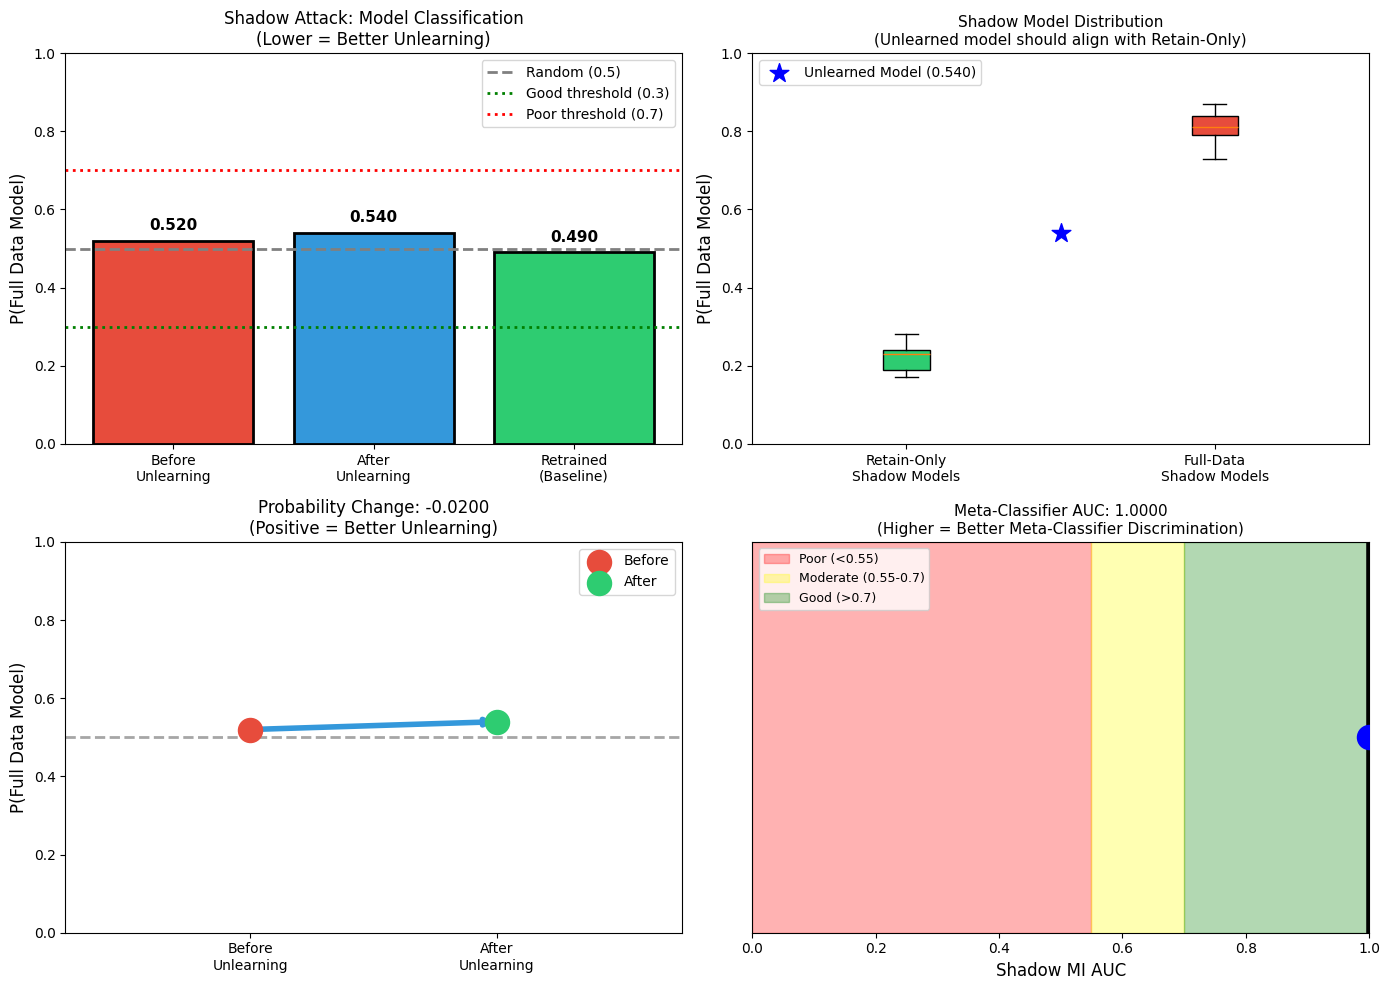


SHADOW MODEL ATTACK SUMMARY

Metric                                        Value               
-----------------------------------------------------------------
P(Full Data) - Before Unlearning              0.5200
P(Full Data) - After Unlearning               0.5400
Probability Change                            -0.0200
Shadow MI AUC (Meta-Classifier)               1.0000
N Shadow Models (per category)                5

-----------------------------------------------------------------
INTERPRETATION:
  • P(Full Data) after unlearning: 0.5400
    ✓ GOOD - Unlearned model shows minimal target data traces

  • Shadow MI AUC: 1.0000
    ✓ Meta-classifier effectively distinguishes model types


In [39]:
# Visualize Shadow Model Attack Results
def visualize_shadow_attack_results(results):
    """Comprehensive visualization of Shadow Model Attack results."""
    attack_results = results['attack_results']
    shadow_attack = results['shadow_attack']
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Plot 1: Model Classification Probabilities
    ax1 = axes[0, 0]
    models = ['Before\nUnlearning', 'After\nUnlearning']
    probs = [
        attack_results['result_before']['prob_full_data'],
        attack_results['result_after']['prob_full_data']
    ]
    
    if attack_results['result_retrained'] is not None:
        models.append('Retrained\n(Baseline)')
        probs.append(attack_results['result_retrained']['prob_full_data'])
    
    colors = ['#e74c3c', '#3498db', '#2ecc71'][:len(models)]
    bars = ax1.bar(models, probs, color=colors, edgecolor='black', linewidth=2)
    
    # Add threshold lines
    ax1.axhline(y=0.5, color='gray', linestyle='--', linewidth=2, label='Random (0.5)')
    ax1.axhline(y=0.3, color='green', linestyle=':', linewidth=2, label='Good threshold (0.3)')
    ax1.axhline(y=0.7, color='red', linestyle=':', linewidth=2, label='Poor threshold (0.7)')
    
    ax1.set_ylabel('P(Full Data Model)', fontsize=12)
    ax1.set_title('Shadow Attack: Model Classification\n(Lower = Better Unlearning)', fontsize=12)
    ax1.set_ylim(0, 1)
    ax1.legend(loc='upper right')
    
    # Add value labels on bars
    for bar, prob in zip(bars, probs):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{prob:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # Plot 2: Shadow Model Distribution
    ax2 = axes[0, 1]
    retain_probs = [shadow_attack.attack_model(m)['prob_full_data'] 
                   for m in shadow_attack.shadow_models_retain]
    full_probs = [shadow_attack.attack_model(m)['prob_full_data'] 
                 for m in shadow_attack.shadow_models_full]
    
    # Box plot
    bp = ax2.boxplot([retain_probs, full_probs], labels=['Retain-Only\nShadow Models', 'Full-Data\nShadow Models'],
                     patch_artist=True)
    bp['boxes'][0].set_facecolor('#2ecc71')
    bp['boxes'][1].set_facecolor('#e74c3c')
    
    # Add target model point
    target_prob = attack_results['result_after']['prob_full_data']
    ax2.scatter([1.5], [target_prob], color='blue', s=200, zorder=5, 
               marker='*', label=f'Unlearned Model ({target_prob:.3f})')
    
    ax2.set_ylabel('P(Full Data Model)', fontsize=12)
    ax2.set_title('Shadow Model Distribution\n(Unlearned model should align with Retain-Only)', fontsize=11)
    ax2.legend(loc='upper left')
    ax2.set_ylim(0, 1)
    
    # Plot 3: Probability Change
    ax3 = axes[1, 0]
    prob_before = attack_results['result_before']['prob_full_data']
    prob_after = attack_results['result_after']['prob_full_data']
    change = prob_before - prob_after
    
    # Arrow diagram
    ax3.annotate('', xy=(0.7, prob_after), xytext=(0.3, prob_before),
                arrowprops=dict(arrowstyle='->', color='#3498db', lw=4))
    
    ax3.scatter([0.3], [prob_before], s=300, color='#e74c3c', zorder=5, label='Before')
    ax3.scatter([0.7], [prob_after], s=300, color='#2ecc71', zorder=5, label='After')
    
    ax3.axhline(y=0.5, color='gray', linestyle='--', linewidth=2, alpha=0.7)
    ax3.set_xlim(0, 1)
    ax3.set_ylim(0, 1)
    ax3.set_ylabel('P(Full Data Model)', fontsize=12)
    ax3.set_title(f'Probability Change: {change:+.4f}\n(Positive = Better Unlearning)', fontsize=12)
    ax3.legend(loc='upper right')
    ax3.set_xticks([0.3, 0.7])
    ax3.set_xticklabels(['Before\nUnlearning', 'After\nUnlearning'])
    
    # Plot 4: Shadow MI AUC Gauge
    ax4 = axes[1, 1]
    shadow_auc = attack_results['shadow_auc']
    
    # Create gauge
    theta = np.linspace(0, np.pi, 100)
    
    # Color zones (inverted - low AUC is good for distinguishing)
    ax4.fill_betweenx([0, 1], 0, 0.55, alpha=0.3, color='red', label='Poor (<0.55)')
    ax4.fill_betweenx([0, 1], 0.55, 0.7, alpha=0.3, color='yellow', label='Moderate (0.55-0.7)')
    ax4.fill_betweenx([0, 1], 0.7, 1.0, alpha=0.3, color='green', label='Good (>0.7)')
    
    # AUC marker
    ax4.axvline(x=shadow_auc, color='black', linewidth=4)
    ax4.scatter([shadow_auc], [0.5], s=300, color='blue', zorder=5)
    
    ax4.set_xlim(0, 1)
    ax4.set_ylim(0, 1)
    ax4.set_xlabel('Shadow MI AUC', fontsize=12)
    ax4.set_title(f'Meta-Classifier AUC: {shadow_auc:.4f}\n(Higher = Better Meta-Classifier Discrimination)', fontsize=11)
    ax4.legend(loc='upper left', fontsize=9)
    ax4.set_yticks([])
    
    plt.tight_layout()
    plt.savefig('shadow_attack_results.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # Print summary
    print("\n" + "="*70)
    print("SHADOW MODEL ATTACK SUMMARY")
    print("="*70)
    print(f"\n{'Metric':<45} {'Value':<20}")
    print("-"*65)
    print(f"{'P(Full Data) - Before Unlearning':<45} {prob_before:.4f}")
    print(f"{'P(Full Data) - After Unlearning':<45} {prob_after:.4f}")
    print(f"{'Probability Change':<45} {change:+.4f}")
    print(f"{'Shadow MI AUC (Meta-Classifier)':<45} {shadow_auc:.4f}")
    print(f"{'N Shadow Models (per category)':<45} {results['n_shadow_models']}")
    
    # Verdict interpretation
    print("\n" + "-"*65)
    print("INTERPRETATION:")
    print(f"  • P(Full Data) after unlearning: {prob_after:.4f}")
    if prob_after < 0.4:
        print("    ✓ EXCELLENT - Unlearned model indistinguishable from retain-only")
    elif prob_after < 0.55:
        print("    ✓ GOOD - Unlearned model shows minimal target data traces")
    elif prob_after < 0.7:
        print("    ⚠ MODERATE - Some traces of target data remain")
    else:
        print("    ✗ POOR - Model still resembles full-data trained model")
    
    print(f"\n  • Shadow MI AUC: {shadow_auc:.4f}")
    if shadow_auc > 0.8:
        print("    ✓ Meta-classifier effectively distinguishes model types")
    elif shadow_auc > 0.6:
        print("    ~ Meta-classifier has moderate discrimination power")
    else:
        print("    ⚠ Meta-classifier struggles to distinguish models")


# Run visualization
if 'results_shadow' in dir():
    visualize_shadow_attack_results(results_shadow)


## 8.5 Comprehensive Verification Attack Comparison

This section compares all four unlearning verification approaches:

| Attack Type | What It Measures | Success Metric | Expected After Unlearning |
|------------|------------------|----------------|---------------------------|
| **Output MIA** | Membership from logits | AUC ≈ 0.5 | Cannot distinguish members |
| **Gradient-MIA** | Membership from gradients | AUC ≈ 0.5, Gradient change magnitude | Gradient patterns changed |
| **FUMA** | Forensic artifacts | Detection rate < 5% | Minimal behavioral traces |
| **Shadow Model** | Model-level fingerprints | P(full data) < 0.5 | Indistinguishable from retain-only |


In [ ]:
def comprehensive_verification_comparison(results_dict):
    """
    Compare all verification attacks and provide unified verdict.
    
    Args:
        results_dict: Dictionary containing results from different attacks
                     Keys: 'output_mia', 'gradient_mia', 'fuma', 'shadow'
    """
    print("="*80)
    print("COMPREHENSIVE UNLEARNING VERIFICATION REPORT")
    print("="*80)
    
    metrics = {}
    verdicts = {}
    
    # 1. Output-based MIA
    if 'output_mia' in results_dict and results_dict['output_mia'] is not None:
        mia = results_dict['output_mia']
        auc = mia.get('unlearn_auc', 0.5)
        metrics['Output MIA AUC'] = auc
        verdicts['output_mia'] = auc < 0.55
        print(f"\n[Output-based MIA]")
        print(f"  AUC on unlearned samples: {auc:.4f}")
        print(f"  Verdict: {'✓ PASS' if auc < 0.55 else '✗ FAIL'} (target: AUC ≈ 0.5)")
    
    # 2. Gradient-based MIA
    if 'gradient_mia' in results_dict and results_dict['gradient_mia'] is not None:
        grad = results_dict['gradient_mia']
        _ga = grad.get('gradient_mia_auc', 0.5)
        grad_auc = float(_ga) if _ga is not None else 0.5
        _gc = grad.get('gradient_change_magnitude', 0)
        grad_change = float(_gc) if _gc is not None else 0.0
        metrics['Gradient MIA AUC'] = grad_auc
        metrics['Gradient Change'] = grad_change
        verdicts['gradient_mia'] = grad_auc < 0.6 or grad_change > 0.1
        print(f"\n[Gradient-based MIA]")
        print(f"  Gradient MIA AUC: {grad_auc:.4f}")
        print(f"  Gradient Change Magnitude: {grad_change:.4f}")
        print(f"  Verdict: {'✓ PASS' if verdicts['gradient_mia'] else '✗ FAIL'}")
    
    # 3. FUMA
    if 'fuma' in results_dict and results_dict['fuma'] is not None:
        fuma = results_dict['fuma']
        detection_rate = fuma.get('detection_rate', 1.0)
        metrics['FUMA Detection Rate'] = detection_rate
        verdicts['fuma'] = detection_rate < 0.20
        print(f"\n[Forensic Unlearning Membership Attack (FUMA)]")
        print(f"  Detection Rate: {detection_rate*100:.2f}%")
        print(f"  Verdict: {'✓ PASS' if detection_rate < 0.05 else ('⚠ MARGINAL' if detection_rate < 0.20 else '✗ FAIL')} (target: <5%)")
    
    # 4. Shadow Model Attack
    if 'shadow' in results_dict and results_dict['shadow'] is not None:
        shadow = results_dict['shadow']
        prob_after = shadow['attack_results']['result_after']['prob_full_data']
        shadow_auc = shadow['attack_results']['shadow_auc']
        metrics['Shadow P(Full Data)'] = prob_after
        metrics['Shadow MI AUC'] = shadow_auc
        verdicts['shadow'] = prob_after < 0.55
        print(f"\n[Shadow Model Attack]")
        print(f"  P(Full Data) After Unlearning: {prob_after:.4f}")
        print(f"  Shadow MI AUC: {shadow_auc:.4f}")
        print(f"  Verdict: {'✓ PASS' if prob_after < 0.5 else '✗ FAIL'} (target: P(full) ≈ 0.5)")
    
    # Overall verdict
    print("\n" + "="*80)
    print("OVERALL VERIFICATION VERDICT")
    print("="*80)
    
    passed = sum(verdicts.values())
    total = len(verdicts)
    
    print(f"\nPassed: {passed}/{total} verification attacks")
    
    if passed == total:
        overall = "✓ UNLEARNING VERIFIED - All attacks passed"
        color = 'green'
    elif passed >= total * 0.75:
        overall = "⚠ UNLEARNING MOSTLY SUCCESSFUL - Most attacks passed"
        color = 'yellow'
    elif passed >= total * 0.5:
        overall = "⚠ UNLEARNING PARTIAL - Mixed results"
        color = 'orange'
    else:
        overall = "✗ UNLEARNING FAILED - Majority of attacks detected traces"
        color = 'red'
    
    print(f"\n{overall}")
    
    # Visualization
    if len(metrics) > 0:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # Plot 1: Metrics comparison
        ax1 = axes[0]
        metric_names = list(metrics.keys())
        metric_values = list(metrics.values())
        
        colors = []
        for name, val in zip(metric_names, metric_values):
            if 'AUC' in name:
                colors.append('#2ecc71' if val < 0.55 else '#e74c3c')
            elif 'Detection' in name:
                colors.append('#2ecc71' if val < 0.05 else ('#f39c12' if val < 0.2 else '#e74c3c'))
            elif 'P(Full' in name:
                colors.append('#2ecc71' if val < 0.5 else '#e74c3c')
            else:
                colors.append('#3498db')
        
        bars = ax1.barh(metric_names, metric_values, color=colors, edgecolor='black')
        ax1.set_xlabel('Value', fontsize=12)
        ax1.set_title('Verification Metrics Comparison', fontsize=12)
        ax1.axvline(x=0.5, color='gray', linestyle='--', label='Target (0.5)')
        
        # Add value labels
        for bar, val in zip(bars, metric_values):
            ax1.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
                    f'{val:.3f}', va='center', fontsize=10)
        
        # Plot 2: Pass/Fail summary
        ax2 = axes[1]
        attack_names = list(verdicts.keys())
        attack_results = ['PASS' if v else 'FAIL' for v in verdicts.values()]
        colors_pf = ['#2ecc71' if v else '#e74c3c' for v in verdicts.values()]
        
        ax2.barh(attack_names, [1]*len(attack_names), color=colors_pf, edgecolor='black')
        for i, (name, result) in enumerate(zip(attack_names, attack_results)):
            ax2.text(0.5, i, result, ha='center', va='center', fontsize=14, 
                    fontweight='bold', color='white')
        
        ax2.set_xlim(0, 1)
        ax2.set_xticks([])
        ax2.set_title('Attack Pass/Fail Summary', fontsize=12)
        
        plt.tight_layout()
        plt.savefig('comprehensive_verification.png', dpi=150, bbox_inches='tight')
        plt.show()
    
    return {
        'metrics': metrics,
        'verdicts': verdicts,
        'overall_passed': passed,
        'overall_total': total,
        'overall_verdict': overall
    }


# Run comprehensive comparison if results are available
print("Attempting to run comprehensive verification comparison...")
print("(This requires running Output MIA, Gradient-MIA, FUMA, and Shadow attacks first)\n")

# Collect available results
verification_results = {}

# Check for Shadow Model results (most recent)
if 'results_shadow' in dir():
    verification_results['shadow'] = results_shadow
    print("✓ Shadow Model Attack results found")

# Check for FUMA results  
if 'results_fuma' in dir():
    verification_results['fuma'] = {
        'detection_rate': results_fuma.get('fuma_results', {}).get('detection_results', {}).get('detection_rate', None)
    }
    print("✓ FUMA results found")

# Check for Gradient-MIA results
if 'results_adult_verified' in dir():
    verification_results['gradient_mia'] = {
        'gradient_mia_auc': results_adult_verified.get('verification_results', {}).get('gradient_mia_auc', None),
        'gradient_change_magnitude': results_adult_verified.get('verification_results', {}).get('gradient_change_magnitude', None)
    }
    print("✓ Gradient-MIA results found")

# Run comparison if we have any results
if len(verification_results) > 0:
    comparison_results = comprehensive_verification_comparison(verification_results)
else:
    print("\nNo verification results available. Please run the attack pipelines first.")


Attempting to run comprehensive verification comparison...
(This requires running Output MIA, Gradient-MIA, FUMA, and Shadow attacks first)

✓ Shadow Model Attack results found
✓ FUMA results found
✓ Gradient-MIA results found
COMPREHENSIVE UNLEARNING VERIFICATION REPORT


TypeError: '<' not supported between instances of 'NoneType' and 'float'

In [43]:
comparison_data = {
    'Aspect': [
        'Data Distribution',
        'Unlearning Target',
        'Communication Pattern',
        'Label Holder',
        'Gradient Direction',
        'Key Methods',
        'Main Challenge',
        'Verification'
    ],
    'HFL Unlearning': [
        'Samples distributed across clients',
        'Client data / specific samples',
        'Gradients aggregated at server',
        'Each client has own labels',
        'Subtract historical gradients',
        'FedEraser, SISA, FRU',
        'Gradient storage overhead',
        'MIA, model output difference'
    ],
    'VFL Unlearning': [
        'Features distributed across parties',
        'Client features / samples / labels',
        'Embeddings exchanged between parties',
        'Single active party holds labels',
        'Gradient ascent on target samples',
        'VFU-GA, VFU-KD, VFU-LR',
        'Feature correlation preservation',
        'MIA, embedding similarity'
    ]
}

comparison_df = pd.DataFrame(comparison_data)
print("HFL vs VFL Unlearning Comparison")
print("=" * 80)
print(comparison_df.to_string(index=False))


HFL vs VFL Unlearning Comparison
               Aspect                     HFL Unlearning                       VFL Unlearning
    Data Distribution Samples distributed across clients  Features distributed across parties
    Unlearning Target     Client data / specific samples   Client features / samples / labels
Communication Pattern     Gradients aggregated at server Embeddings exchanged between parties
         Label Holder         Each client has own labels     Single active party holds labels
   Gradient Direction      Subtract historical gradients    Gradient ascent on target samples
          Key Methods               FedEraser, SISA, FRU               VFU-GA, VFU-KD, VFU-LR
       Main Challenge          Gradient storage overhead     Feature correlation preservation
         Verification       MIA, model output difference            MIA, embedding similarity


## 13. Experimental Results Summary


In [ ]:
# Summary table
summary_data = {
    'Dataset': ['UCI Adult', 'German Credit'],
    'Samples': [X_adult.shape[0], X_german.shape[0]],
    'Features': [X_adult.shape[1], X_german.shape[1]],
    'Parties': [2, 2],
    'Pre-Unlearn Acc': [
        f"{results_ga['before']['accuracy']:.4f}",
        f"{results_german['before']['accuracy']:.4f}"
    ],
    'Post-Unlearn Acc': [
        f"{results_ga['after']['accuracy']:.4f}",
        f"{results_german['after']['accuracy']:.4f}"
    ],
    'Utility Drop (%)': [
        f"{results_ga['utility_drop']*100:.2f}",
        f"{results_german['utility_drop']*100:.2f}"
    ]
}

summary_df = pd.DataFrame(summary_data)
print("\nExperimental Results Summary")
print("=" * 80)
print(summary_df.to_string(index=False))


## 14. References

### Horizontal Federated Learning Unlearning

1. **FedEraser** - Liu et al. (2021): "FedEraser: Enabling Efficient Client-Level Data Removal from Federated Learning Models"
2. **SISA** - Bourtoule et al. (2021): "Machine Unlearning" (NeurIPS)
3. **FedRecover** - Cao et al. (2023): "FedRecover: Recovering from Poisoning Attacks in Federated Learning using Historical Information"
4. **KNOT** - Su et al. (2023): "Asynchronous Federated Unlearning"
5. **FRU** - Yuan et al. (2023): "Federated Unlearning via Class-Discriminative Pruning"

### Vertical Federated Learning Unlearning

1. **VFU-LR** - Deng et al. (2023): "Vertical Federated Unlearning on the Logistic Regression Model"
2. **Few-shot Label Unlearning** - Gu et al. (2024): "A few-shot Label Unlearning in Vertical Federated Learning"
3. **VFU-KD/VFU-GA** - Varshney et al. (2025): "Unlearning Clients, Features and Samples in Vertical Federated Learning"
4. **Certified VFL Unlearning** - Wang & Wang (2025): "Forgetting Any Data at Any Time: A Theoretically Certified Unlearning Framework for Vertical Federated Learning"

### Surveys

1. Liu et al. (2024): "A Survey on Federated Unlearning: Challenges, Methods, and Future Directions"
2. Xu et al. (2024): "Machine Unlearning: A Survey"


In [ ]:
# Save models for future use
import os

os.makedirs('models', exist_ok=True)

# Save model states
torch.save({
    'bottom_models': [m.state_dict() for m in vfl_model_adult.bottom_models],
    'top_model': vfl_model_adult.top_model.state_dict()
}, 'models/vfl_adult.pt')

torch.save({
    'bottom_models': [m.state_dict() for m in vfl_model_german.bottom_models],
    'top_model': vfl_model_german.top_model.state_dict()
}, 'models/vfl_german.pt')

torch.save({
    'bottom_models': [m.state_dict() for m in vfl_model_mimic.bottom_models],
    'top_model': vfl_model_mimic.top_model.state_dict()
}, 'models/vfl_mimic.pt')

print("Models saved to 'models/' directory")


In [ ]:
# Plot training history
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history_adult['train_loss'], color='#2ecc71', linewidth=2)
axes[0].set_title('Training Loss', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_adult['val_acc'], label='Accuracy', color='#3498db', linewidth=2)
axes[1].plot(history_adult['val_f1'], label='F1 Score', color='#e74c3c', linewidth=2)
axes[1].set_title('Validation Metrics', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(history_adult['val_auc'], color='#9b59b6', linewidth=2)
axes[2].set_title('Validation AUC', fontsize=12)
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('AUC')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_history_adult.png', dpi=150, bbox_inches='tight')
plt.show()
